# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | Team 10 · **team number** (from the LMS list): 10 |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** GoMart should add riders in the two rush windows, 11:00 to 12:59 and 18:00 to 20:59, and start in the Outer zone, because customers wait longest and rate the service lowest then and there.

Five rush hours bring 46% of all orders. In those hours deliveries take about 8 minutes longer in every zone, and the Outer zone's median wait is 52.5 minutes. Ratings fall from 4.6 stars for waits up to 25 minutes to 2.2 above 55. My group sees an association, not proof, so a rider pilot in the Outer zone should test it.

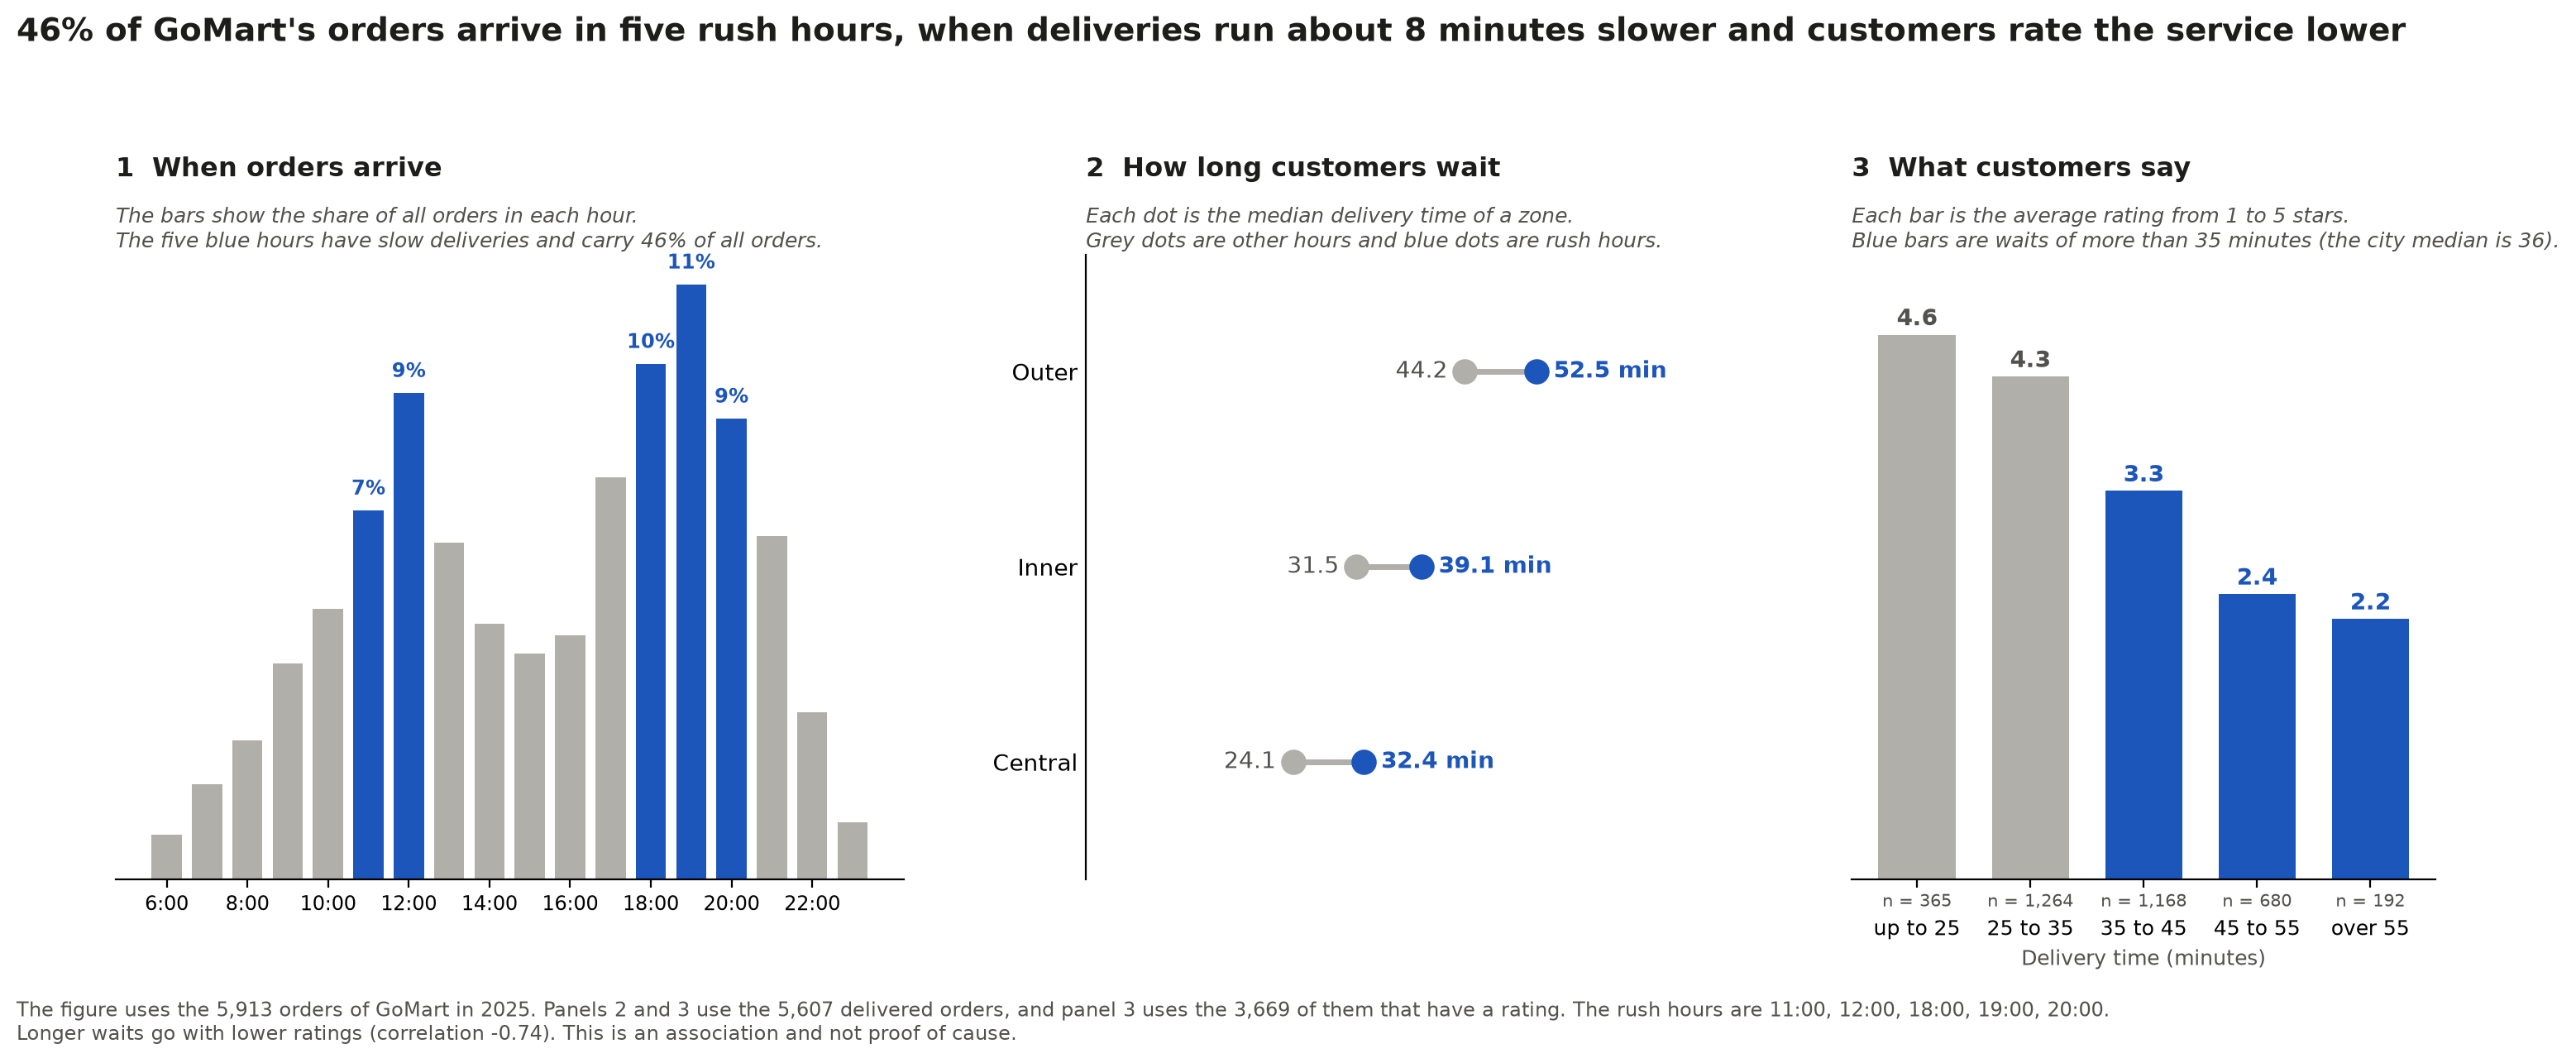

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

My group moved this Setup section above Task 0, so that the Task 0 cells can use the helper functions below when the notebook runs from top to bottom.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered from light to dark

In [2]:
from pathlib import Path
DATA = Path("../../data/raw")                    # inside our repository
if not (DATA / "gomart_orders_2025_clean.csv").exists():
    DATA = Path(".")                             # files uploaded next to the notebook (Colab, LMS)
orders = pd.read_csv(DATA / "gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv(DATA / "gomart_districts.csv")
targets = pd.read_csv(DATA / "gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

(5913, 16) | orders without zone: 0


Helper functions from Tutorial 3 (given):

In [3]:
from matplotlib.backends.backend_agg import FigureCanvasAgg

def fig_to_rgb(fig):
    canvas = FigureCanvasAgg(fig)                 # my group draws on an Agg canvas: after plt.show() the canvas of a figure
    canvas.draw()                                 # may no longer have buffer_rgba(), so the Task 3 tests would fail
    return np.asarray(canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P10 · *The Price of Dinner*. My group compares food prices in wet markets, supermarkets and delivery apps with the official consumer price index (CPI).

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [4]:
# Task 0: house_style.py v0 for project P10, The Price of Dinner
# My group gives every choice one comment that explains it.
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm

# Categorical palette in a fixed order: the three channels keep these colours in every chart of the project.
CHANNELS = ["Wet market", "Supermarket", "Delivery app"]
CHANNEL_COLOR = {
    "Wet market": "#1d56ba",    # blue: the traditional channel, and the darkest of the three in greyscale
    "Supermarket": "#d9622b",   # orange: a warm hue that colour-blind readers still separate from blue
    "Delivery app": "#7cc4bb",  # light teal: the lightest channel colour, so it stays apart in greyscale
}
CPI_COLOR = "#1f1f1d"           # near black: the official CPI is the benchmark, so it gets the strongest ink
CONTEXT = "#dcdbd5"             # light grey: items that are not the point of a chart
TEXT, NOTE = "#1d1d1b", "#52514e"   # dark grey for titles and labels, softer grey for notes and sources

# One sequential map and one diverging map
SEQ_CMAP = "cividis"            # sequential: its lightness rises evenly and it was built for colour-vision deficiency
DIV_CMAP = "RdBu_r"             # diverging: blue for prices that fell and red for prices that rose
DIV_CENTER = 100                # the middle of the diverging map is 100, the price index of the base week
SIGNED = "{:+.1f}%"             # added after the greyscale test: both ends of RdBu_r turn dark grey, so every
                                # diverging chart also prints the sign of the change, for example +2.4% or -1.1%


def div_norm(vmin, vmax):
    """Keep the white middle of the diverging map at the base week, whatever the range of the data is."""
    return TwoSlopeNorm(vmin=vmin, vcenter=DIV_CENTER, vmax=vmax)


# Number formats
def vnd(x, pos=None):
    """Prices in VND with a thousands separator, for example 25,000 VND."""
    return f"{x:,.0f} VND"


def pct(x, pos=None):
    """Percent changes with one decimal, for example 4.5%."""
    return f"{x:.1f}%"


DATE_FORMAT = "%d %b %Y"        # dates such as 03 Oct 2026: the day comes first, as readers in Vietnam expect
WEEK_LABEL = "Week {:02d}"      # survey weeks such as Week 03, so that the labels sort in the right order


def use_house_style():
    """Apply the house style of my group to every chart drawn after this call."""
    mpl.rcParams.update({
        "font.family": "DejaVu Sans",          # it comes with matplotlib, so the charts look the same on every computer
        "font.size": 10,                       # body text that stays readable on a laptop screen
        "axes.titlesize": 12.5,                # chart titles are larger than the body text
        "axes.titleweight": "bold",            # titles carry the finding, so they are bold
        "axes.titlelocation": "left",          # a title on the left reads like a newspaper headline
        "axes.labelcolor": TEXT, "xtick.color": TEXT, "ytick.color": TEXT,
        "axes.edgecolor": "#a3a29d",           # a soft grey axis line instead of black
        "axes.spines.top": False, "axes.spines.right": False,   # less frame and more room for the data
        "axes.grid": False,                    # my group labels values directly instead of drawing gridlines
        "axes.prop_cycle": mpl.cycler(color=[CHANNEL_COLOR[c] for c in CHANNELS] + [CPI_COLOR]),
        "legend.frameon": False,
        "figure.facecolor": "white", "savefig.facecolor": "white",
        "savefig.dpi": 200, "savefig.bbox": "tight",
    })


print("House style v0 for P10 is defined. Channels in fixed order:", CHANNELS)

House style v0 for P10 is defined. Channels in fixed order: ['Wet market', 'Supermarket', 'Delivery app']


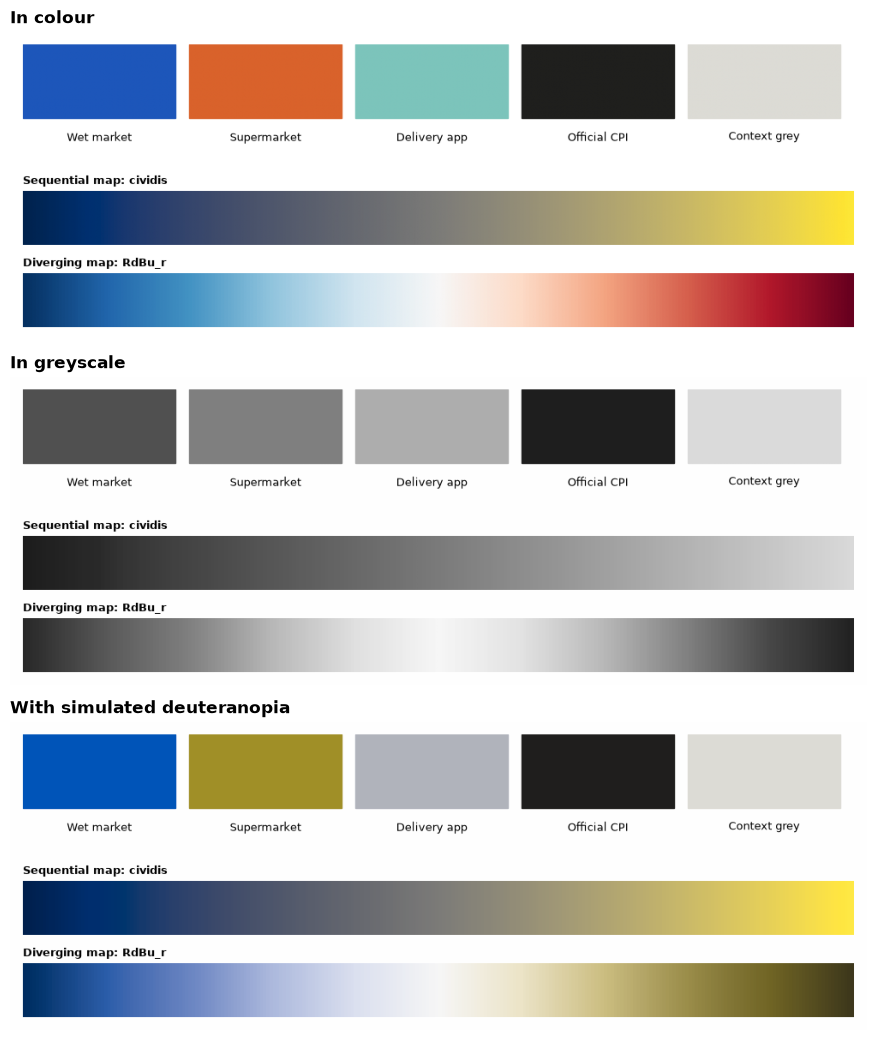

Lightness in greyscale (0 = black, 1 = white): {'Wet market': np.float64(0.32), 'Supermarket': np.float64(0.5), 'Delivery app': np.float64(0.68), 'Official CPI': np.float64(0.12), 'Context grey': np.float64(0.86)}
Smallest lightness gap in greyscale: 0.18 (Delivery app and Context grey)
Smallest colour distance with deuteranopia: 0.25 (Delivery app and Context grey)


In [5]:
# Task 0 evidence: the palette and both colour maps in colour, in greyscale and with simulated deuteranopia
SWATCH = {**CHANNEL_COLOR, "Official CPI": CPI_COLOR, "Context grey": CONTEXT}

with mpl.rc_context():                    # the P10 style stays inside this cell, so the GoMart charts keep their own
    use_house_style()
    pal_fig, axs = plt.subplots(3, 1, figsize=(10, 3.6), gridspec_kw={"height_ratios": [2.2, 1, 1]})
    for i, (name, colour) in enumerate(SWATCH.items()):
        axs[0].add_patch(plt.Rectangle((i, 0), 0.92, 1, color=colour))
        axs[0].text(i + 0.46, -0.18, name, ha="center", va="top", fontsize=9)
    axs[0].set_xlim(0, len(SWATCH)); axs[0].set_ylim(-0.6, 1)
    ramp = np.linspace(0, 1, 256)[None, :]
    axs[1].imshow(ramp, cmap=SEQ_CMAP, aspect="auto"); axs[1].set_title(f"Sequential map: {SEQ_CMAP}", fontsize=9)
    axs[2].imshow(ramp, cmap=DIV_CMAP, aspect="auto"); axs[2].set_title(f"Diverging map: {DIV_CMAP}", fontsize=9)
    for ax in axs:
        ax.axis("off")
    pal_fig.tight_layout()
    pal_rgb = fig_to_rgb(pal_fig)
    plt.close(pal_fig)

    views = {"In colour": pal_rgb, "In greyscale": np.dstack([to_grey(pal_rgb)] * 3),
             "With simulated deuteranopia": simulate_cvd(pal_rgb)}
    swatch_fig, axs = plt.subplots(3, 1, figsize=(10, 10.5))
    for ax, (label, img) in zip(axs, views.items()):
        ax.imshow(np.clip(img, 0, 1)); ax.set_title(label); ax.axis("off")
    swatch_fig.tight_layout()
    plt.show()

# The numbers behind the test: lightness in greyscale and the distance between colours with deuteranopia
rgb = np.array([to_rgb(c) for c in SWATCH.values()])
grey_values = to_grey(rgb)
deutan = simulate_cvd(rgb)
names = list(SWATCH)
print("Lightness in greyscale (0 = black, 1 = white):", dict(zip(names, grey_values.round(2))))
pairs = [(abs(grey_values[i] - grey_values[j]), np.linalg.norm(deutan[i] - deutan[j]), names[i], names[j])
         for i in range(len(names)) for j in range(i + 1, len(names))]
g, _, a, b = min(pairs)
print(f"Smallest lightness gap in greyscale: {g:.2f} ({a} and {b})")
_, d, a, b = min(pairs, key=lambda p: p[1])
print(f"Smallest colour distance with deuteranopia: {d:.2f} ({a} and {b})")

**What the test shows.** In greyscale the five colours keep five clearly different lightness levels, from 0.12 for the official CPI to 0.86 for the context grey, and the smallest gap is 0.18 (delivery app and context grey). With simulated deuteranopia the blue, the olive version of the orange and the grey version of the teal stay apart, so no two colours collide and my group kept the palette. The sequential map cividis keeps its order in greyscale.

The test showed one problem. In greyscale both ends of the diverging map RdBu_r turn dark, so a reader cannot tell a price rise from a price fall by colour alone. My group therefore added one rule to the house style (`SIGNED` in the cell above): every diverging chart also prints the sign of the change on its labels, for example +2.4% and -1.1%.

**Makeover plan.** My group chose Figure 5 on page 13 of the report *Tổng quan thị trường giá cả tháng 9, quý III và 9 tháng năm 2026* (Overview of prices in September, the third quarter and the first nine months of 2026) by the Cục Thống kê (National Statistics Office, Ministry of Finance). The report is dated 30 September 2026 and was published on 3 October 2026 with the [press release](https://www.nso.gov.vn/tin-tuc-thong-ke/2026/10/thong-cao-bao-chi-ve-tinh-hinh-gia-thang-chin-quy-iii-va-9-thang-nam-2026/). My group accessed the report on 19 October 2026 through this link: [PDF](https://www.nso.gov.vn/wp-content/uploads/2026/10/Tong-quan-CPI-chi-so-gia-vang-do-la-My-thang-9-QIII-va-9-thang-nam-2026.pdf).

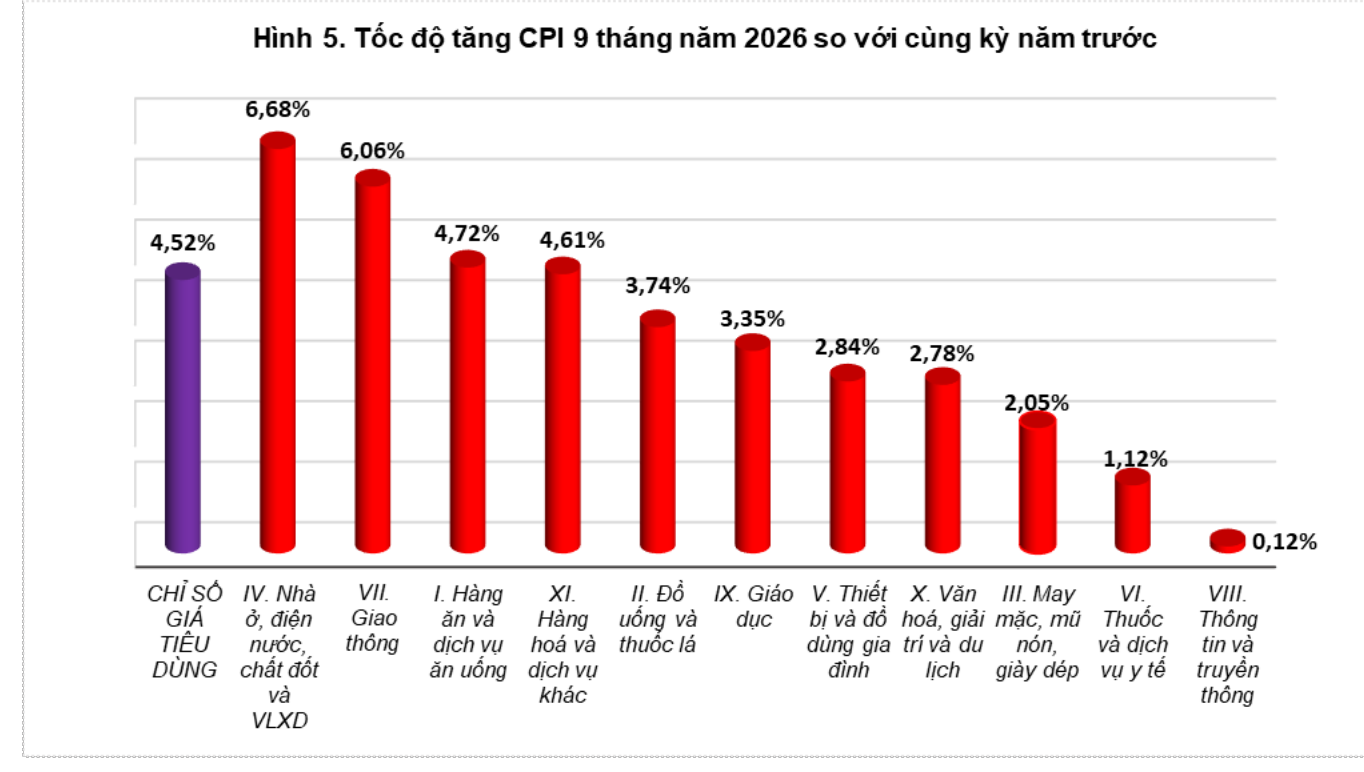

Figure 5 shows how much the prices of each of the 11 groups of goods and services rose in the first nine months of 2026, compared with the same months of 2025. The text under the chart asks the reader which groups pushed the CPI up, so my group takes that as the task of the chart. In my group's opinion, the chart answers this question badly, for the reasons below.

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | Every bar is a shaded 3D cylinder with an oval top, and the smallest group (0.12%) appears only as a red disc. | Data-ink and expressiveness | The reader has to judge where an oval top ends, and the 0.12% group looks like a blob instead of a bar that is almost zero. | My group draws flat bars on a common baseline at zero. |
| 2 | The national CPI (4.52%) is drawn as one more bar, in purple, at the left end of the row of groups. | Gestalt similarity and expressiveness | The reader takes the average for a twelfth group and has to compare every red bar with a purple bar far away, so the groups above and below the average are hard to see. | My group draws a reference line at 4.52% across all the groups. |
| 3 | All eleven groups have the same strong red. | Colour job and preattentive attention | Red signals danger for every group, so no group stands out, and the reader cannot find the group that the text discusses. | My group colours all groups grey and uses one dark colour for food and catering, the group that my project studies. |
| 4 | The labels carry Roman numerals from the official list and wrap over up to five lines in small italics. | Short-term memory and effectiveness | The reader has to decode codes such as IV. and XI. and read five short lines under each narrow bar, which slows the reading down. | My group uses horizontal bars with short names on one line. |
| 5 | The chart has horizontal gridlines, but the axis has no numbers. | Data-ink | The gridlines cannot be read, so they add clutter and give the reader nothing. | My group removes the gridlines and puts a value label on every bar. |
| 6 | The chart shows only how fast prices rose. The text under it says that food and catering added the most to the CPI (1.69 percentage points). | Expressiveness (the chart does not fit the task) | The reader concludes that housing and transport drove inflation, while food, the largest driver, looks like an average group. | My group adds a second panel, aligned with the first, that shows how many percentage points each group added to the CPI. |

![Photo of the hand sketch for the Figure 5 redesign](evidence/sketch_task0.jpg)

Groups that rose faster than food: ['Transport', 'Housing, utilities, building materials']
Group with the largest contribution: Food and catering 1.69
Months of 2026 above the same month of 2025: ['Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep']


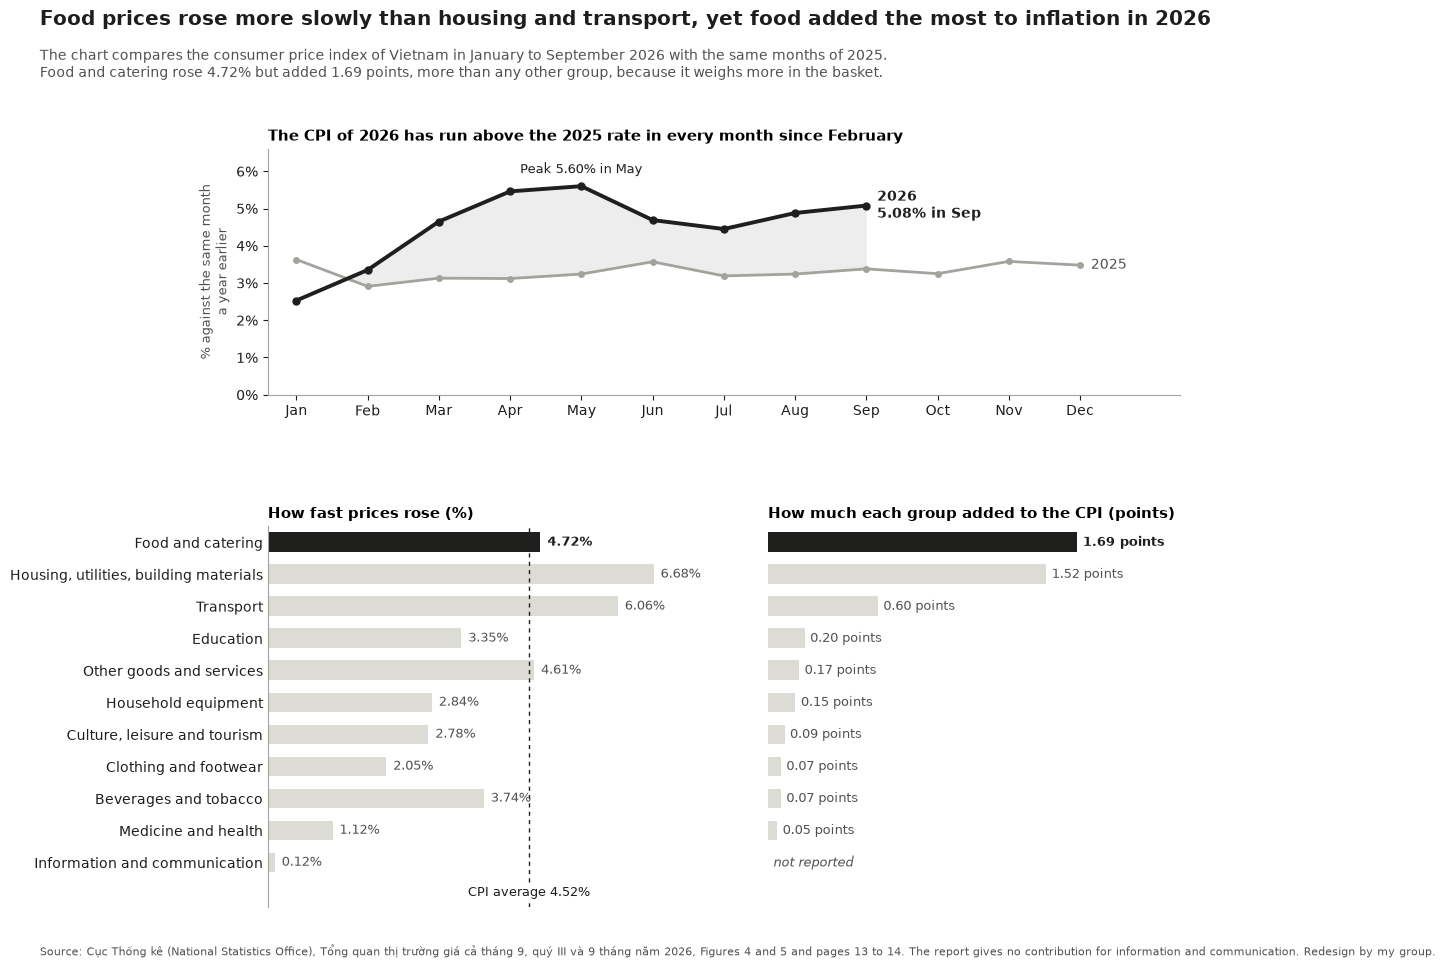

In [6]:
# Task 0: coded redesign of Figure 5, an early version of the M3 makeover.
# My group typed the numbers from the NSO report: the monthly rates from Figure 4 (page 12),
# the group rates from Figure 5 (page 13) and the contributions from the text on pages 13 and 14.
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
FULL_MONTH = dict(zip(MONTHS, ["January", "February", "March", "April", "May", "June", "July", "August",
                               "September", "October", "November", "December"]))
cpi_2025 = [3.63, 2.91, 3.13, 3.12, 3.24, 3.57, 3.19, 3.24, 3.38, 3.25, 3.58, 3.48]   # % against the same month of 2024
cpi_2026 = [2.53, 3.35, 4.65, 5.46, 5.60, 4.69, 4.45, 4.88, 5.08]                     # % against the same month of 2025
CPI_9M = 4.52                                                                         # average of January to September 2026, %
groups = pd.DataFrame({
    "group": ["Housing, utilities, building materials", "Transport", "Food and catering",
              "Other goods and services", "Beverages and tobacco", "Education", "Household equipment",
              "Culture, leisure and tourism", "Clothing and footwear", "Medicine and health",
              "Information and communication"],
    "rate": [6.68, 6.06, 4.72, 4.61, 3.74, 3.35, 2.84, 2.78, 2.05, 1.12, 0.12],     # % against January to September 2025
    "points": [1.52, 0.60, 1.69, 0.17, 0.07, 0.20, 0.15, 0.09, 0.07, 0.05, np.nan],  # percentage points added to the CPI
})
groups = groups.sort_values("points", na_position="first").reset_index(drop=True)   # largest contribution on top
FOCUS = "Food and catering"

food = groups.set_index("group").loc[FOCUS]
months_above = [MONTHS[i] for i in range(len(cpi_2026)) if cpi_2026[i] > cpi_2025[i]]
print("Groups that rose faster than food:", groups.loc[groups["rate"] > food["rate"], "group"].tolist())
print("Group with the largest contribution:", groups.loc[groups["points"].idxmax(), "group"], groups["points"].max())
print("Months of 2026 above the same month of 2025:", months_above)

with mpl.rc_context():
    use_house_style()
    fig0 = plt.figure(figsize=(12, 9.6))
    gs = fig0.add_gridspec(2, 2, height_ratios=[1, 1.55], width_ratios=[1.15, 1], hspace=0.42, wspace=0.06)
    ax_m = fig0.add_subplot(gs[0, :])
    ax_r = fig0.add_subplot(gs[1, 0])
    ax_p = fig0.add_subplot(gs[1, 1], sharey=ax_r)

    # Top: the CPI month by month, 2026 against 2025, with the months where 2026 is higher shaded
    x25, x26 = np.arange(12), np.arange(len(cpi_2026))
    ax_m.fill_between(x26, cpi_2025[:len(cpi_2026)], cpi_2026, where=np.array(cpi_2026) > np.array(cpi_2025[:len(cpi_2026)]),
                      interpolate=True, color=CPI_COLOR, alpha=0.08, lw=0)
    ax_m.plot(x25, cpi_2025, color="#a3a29d", lw=2, marker="o", ms=4)
    ax_m.plot(x26, cpi_2026, color=CPI_COLOR, lw=2.8, marker="o", ms=5)
    ax_m.text(11.15, cpi_2025[-1], "2025", va="center", color=NOTE, fontsize=10)
    ax_m.text(len(cpi_2026) - 1 + 0.15, cpi_2026[-1], f"2026\n{cpi_2026[-1]:.2f}% in Sep", va="center",
              color=CPI_COLOR, fontsize=10, fontweight="bold")
    ax_m.text(4, cpi_2026[4] + 0.35, f"Peak {cpi_2026[4]:.2f}% in May", ha="center", color=CPI_COLOR, fontsize=9)
    ax_m.set_xticks(x25, MONTHS)
    ax_m.set_xlim(-0.4, 12.4)
    ax_m.set_ylim(0, 6.6)
    ax_m.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v:.0f}%"))
    ax_m.set_title(f"The CPI of 2026 has run above the 2025 rate in every month since {FULL_MONTH[months_above[0]]}",
                   fontsize=11)
    ax_m.set_ylabel("% against the same month\na year earlier", color=NOTE, fontsize=9)

    # Bottom left: how fast prices rose, with the national average as a line instead of a bar
    colours = [CPI_COLOR if g == FOCUS else CONTEXT for g in groups["group"]]
    y = np.arange(len(groups))
    ax_r.barh(y, groups["rate"], color=colours, height=0.62)
    ax_r.axvline(CPI_9M, color=CPI_COLOR, lw=1, ls=(0, (3, 3)))
    ax_r.text(CPI_9M, -0.75, f"CPI average {CPI_9M:.2f}%", ha="center", va="top", fontsize=9, color=CPI_COLOR,
              bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    ax_r.set_ylim(-1.4, len(groups) - 0.5)
    for yi, (g, r) in enumerate(zip(groups["group"], groups["rate"])):
        ax_r.text(r + 0.12, yi, f"{r:.2f}%", va="center", fontsize=9,
                  color=CPI_COLOR if g == FOCUS else NOTE, fontweight="bold" if g == FOCUS else "normal")
    ax_r.set_yticks(y, groups["group"])
    ax_r.set_xlim(0, 8.2)
    ax_r.set_xticks([])
    ax_r.spines[["bottom"]].set_visible(False)
    ax_r.tick_params(axis="y", length=0)
    ax_r.set_title("How fast prices rose (%)", fontsize=11)

    # Bottom right: how many percentage points each group added to the CPI
    ax_p.barh(y, groups["points"].fillna(0), color=colours, height=0.62)
    for yi, (g, p) in enumerate(zip(groups["group"], groups["points"])):
        label = "not reported" if np.isnan(p) else f"{p:.2f} points"
        ax_p.text((0 if np.isnan(p) else p) + 0.03, yi, label, va="center", fontsize=9, style="italic" if np.isnan(p) else "normal",
                  color=CPI_COLOR if g == FOCUS else NOTE, fontweight="bold" if g == FOCUS else "normal")
    ax_p.set_xlim(0, 2.25)
    ax_p.set_xticks([])
    ax_p.spines[["bottom", "left"]].set_visible(False)
    ax_p.tick_params(axis="y", length=0, labelleft=False)
    ax_p.set_title("How much each group added to the CPI (points)", fontsize=11)

    fig0.suptitle("Food prices rose more slowly than housing and transport, yet food added the most to inflation in 2026",
                  x=0.02, ha="left", fontsize=14.5, fontweight="bold", color=TEXT, y=0.995)
    fig0.text(0.02, 0.925, "The chart compares the consumer price index of Vietnam in January to September 2026 with the same months of 2025.\n"
              f"Food and catering rose {food['rate']:.2f}% but added {food['points']:.2f} points, more than any other group, "
              "because it weighs more in the basket.", fontsize=10, color=NOTE)
    fig0.text(0.02, 0.01, "Source: Cục Thống kê (National Statistics Office), Tổng quan thị trường giá cả tháng 9, quý III và "
              "9 tháng năm 2026, Figures 4 and 5 and pages 13 to 14. The report gives no contribution for information "
              "and communication. Redesign by my group.", fontsize=8, color=NOTE)
    fig0.subplots_adjust(top=0.85, bottom=0.06, left=0.21, right=0.97)
    plt.show()

**My group's redesign.** My group split the chart into three panels that use only common chart types. The line chart on top gives the context: the CPI of 2026 has run above the rate of 2025 in most months, and the shaded area marks those months. The two bar charts below share one row for each group, so the reader can follow a group from how fast its prices rose (left) to how much it added to the CPI (right). The national average is now a dashed reference line instead of a bar. Food and catering is the only dark group because it is the topic of our project, and the right panel shows the point that the original chart hides: food added the most to inflation even though its prices rose more slowly than housing and transport. The coded version is a first draft; the final version comes with Module M3.

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

My group read the code of every chart and listed the problems that, in my group's opinion, cost the reader the most.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | Compare the number of orders across the 10 districts and rank them. | The chart is a pie with 10 slices of almost equal size (7.1% to 12.8%). | Effectiveness: angle and area are judged less accurately than position on a common scale (Cleveland & McGill) | The reader cannot tell whether Binh Thanh or Tan Binh is larger and cannot see that the largest district has 1.8 times the orders of the smallest. |
| 1 | | The 10 slices use the `jet` rainbow and a separate legend with 10 entries, and the slice labels repeat the legend. | Colour job and short-term memory: ten colour and name pairs are more than the 4 to 7 items that working memory holds | The reader jumps between the legend and the pie and still loses track of which slice is which. |
| 1 | | The slices follow alphabetical order (`sort_index`) instead of their size. | Effectiveness: an ordered quantity needs an ordered layout | The ranking, which is the point of the chart, is hidden, so the reader has to sort ten percentages in their head. |
| 1 | | Every slice has `explode`, `shadow` and a percentage with two decimals (`12.75%`). | Data-ink: decoration and false precision add ink that carries no information | The shadows and gaps pull the eye away from the size differences, and the long numbers are slow to scan. |
| 1 | | The rainbow becomes an uneven grey ramp, and several neighbouring slices merge under deuteranopia. | Greyscale and colour-vision deficiency | A reader with a black and white print or with colour-vision deficiency cannot tell many slices apart, even with the legend. |
| 2 Payments | Follow the monthly number of orders and the share of orders that customers paid by e-wallet. | The chart draws two different measures on one plot with two y axes. | Expressiveness: two scales on one plot | Similar slopes suggest a link between the two measures that the scales do not support. |
| 2 | | Both y axes are cut: the orders start at 380 and the e-wallet share starts at 25%. | Expressiveness: the length of a bar must start at zero | The monthly changes look much larger than they are. |
| 2 | | Every month has a different rainbow colour. | Colour job | The colours carry no data and make the bars harder to compare. |
| 2 | | A heavy black grid and two separate legends cover the chart. | Data-ink | The reader spends effort on lines and boxes that carry no data. |
| 2 | | The month labels are rotated and packed close together. | Effectiveness | The reader reads the months slowly. |
| 3 Delivery time | Find where deliveries are slow, and compare each district's delivery time with its distance to the hub. | The y axis starts at 25 minutes (`set_ylim(25, 55)`). | Expressiveness: the length of a bar must start at zero | The bar of Thu Duc City looks about 15 times longer than the bar of District 1, but its delivery time is only 1.9 times longer. |
| 3 | | The districts follow alphabetical order, and "District 10" even comes before "District 3". | Effectiveness: an ordered quantity needs an ordered layout | The reader has to scan all ten bars to find the slowest district. |
| 3 | | Every bar has its own `jet` colour, which only follows the alphabetical position. | Colour job and preattentive attention | Tan Binh, an average district, is bright red and looks like an alarm, while Binh Tan, the second slowest district, is dark navy and looks calm. |
| 3 | | The district names are rotated by 90 degrees and are cut off at the bottom of the figure. | Effectiveness | The reader cannot be sure which bar belongs to which district. |
| 3 | | Every bar carries a label with four decimals, for example 49.5618. | Data-ink and short-term memory | The reader has to read ten long numbers whose decimals carry no meaning for a delivery time. |
| 3 | | The chart does not show the distance to the hub or the zone. | Expressiveness: the chart does not fit the task | The reader cannot answer the second half of the question, whether customers far from the hub wait longer. |
| 4 Peak times | Find the hours and days with the most orders, so that the operations team can plan staff and riders. | The heatmap uses the `jet` rainbow colour map for the number of orders. | Expressiveness: the colour map is not perceptually uniform | The lightness jumps up and down, so the reader sees borders that are not in the data, and in greyscale the busiest cells turn dark. |
| 4 | | The days of the week follow alphabetical order (Friday, Monday, Saturday and so on). | Gestalt continuity | The week loses its natural order, so the reader has to search the rows one by one. |
| 4 | | The title only says "Orders heatmap". | Preattentive attention: the title gives no finding | The manager has to scan the whole chart to find the peak hours. |
| 4 | | The colour bar has no unit and does not start at zero. | Data-ink and expressiveness | The reader cannot tell whether the colour shows orders or revenue, and a scale that does not start at zero distorts the comparison. |
| 5 Targets | Compare the monthly orders of each zone with its target and find the zones and months that missed it. | The three panels use three different y scales. | Effectiveness | The reader misjudges the size of the gaps between zones. |
| 5 | | Red and green bars show whether a month is above or below the target. | Colour-vision deficiency | A reader with red and green colour blindness cannot tell a surplus from a shortfall by colour. |
| 5 | | The title gives no finding. | Preattentive attention | The reader has to inspect all three panels to find the main result. |
| 5 | | No bar is highlighted, so the largest shortfalls do not stand out. | Effectiveness | The reader cannot find the worst month quickly. |
| 5 | | The month labels repeat under every panel, and every panel has a full border. | Data-ink | The extra labels and borders add clutter and slow the reader down. |
| 6 Basket by tier | Compare the typical basket value across the four member tiers, from non-members to Platinum. | Four circles overlap, so the reader has to compare their areas. | Effectiveness: area is judged less accurately than position or length | The reader cannot tell how much larger the Platinum basket is, and the overlaps hide part of every circle. |
| 6 | | The area of each circle grows with the square of the mean (`s=(avg / 1000) ** 2 / 2`), so a Platinum mean that is 34% higher becomes a circle that is 80% larger. | Expressiveness: the size of a mark must follow the data | The reader overestimates the Platinum gap more than two times. |
| 6 | | The tiers follow alphabetical order: Gold, Platinum, Silver, none. | Expressiveness: an ordered attribute needs an ordered layout | The reader cannot follow the ladder from non-member to Platinum. |
| 6 | | Each circle has a rainbow colour (purple, cyan, yellow, red). | Colour job | The colours suggest four unrelated groups and make the red "none" circle look like a warning. |
| 6 | | The chart shows the mean of a skewed variable and no spread. | Effectiveness | The reader cannot see that most baskets of all four tiers overlap. |

## Task 2 · Redesign
In my group's opinion, a redesign has to fit the task of its chart first, so my group chose the chart type before it chose any colour.

### Chart 1 · Orders by district
*Task:* compare the number of orders across the 10 districts and rank them.
*Why this chart:* My group chose a horizontal bar chart sorted by size, because it puts every value on one common baseline, and position on a common scale is the most accurate channel. The district names sit next to the bars, so the chart needs no legend.

*Choices:* The bars start at zero and run from the largest district to the smallest. The two largest districts are blue and the other eight are grey. Every bar carries its count and its share, so my group removed the gridlines, the frame and the legend. The title states the finding.

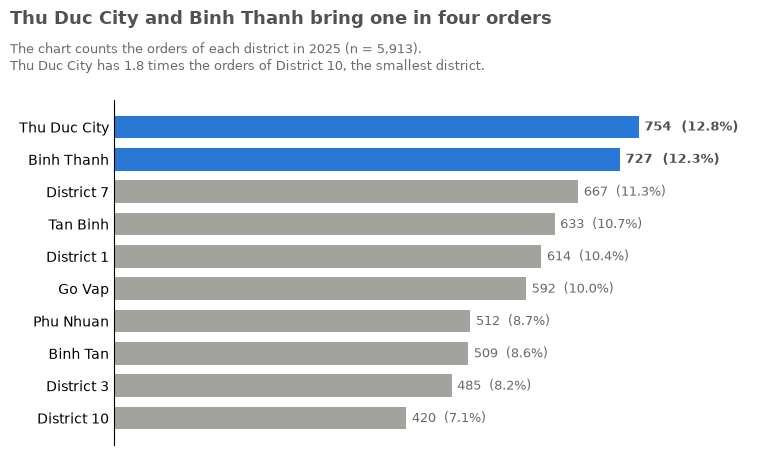

In [7]:
# Chart 1: orders by district as sorted horizontal bars, grey for most districts and blue for the two largest
counts = orders["district"].value_counts()                  # already sorted, largest first
share = counts / counts.sum() * 100
top2 = counts.index[:2]
top2_share = counts[top2].sum() / counts.sum() * 100
ratio = counts.iloc[0] / counts.iloc[-1]

fig, ax = plt.subplots(figsize=(8, 5))
colors = [BLUE if d in top2 else GREY for d in counts.index]
bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
ax.invert_yaxis()                                           # largest at the top
for b, d in zip(bars, counts.index):
    ax.text(b.get_width() + 8, b.get_y() + b.get_height() / 2,
            f"{counts[d]:,}  ({share[d]:.1f}%)", va="center", fontsize=9,
            color=DARK if d in top2 else "#6b6a66", fontweight="bold" if d in top2 else "normal")
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xticks([])                                           # values are labelled directly
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="y", length=0)

fig.suptitle(f"{top2[0]} and {top2[1]} bring one in four orders",
             x=0.02, ha="left", fontsize=13, fontweight="bold", color=DARK)
fig.text(0.02, 0.86, f"The chart counts the orders of each district in 2025 (n = {counts.sum():,}).\n{top2[0]} has {ratio:.1f} times the orders of {counts.index[-1]}, the smallest district.",
         ha="left", fontsize=9.5, color="#6b6a66")
fig.subplots_adjust(top=0.8, left=0.15, right=0.97)
fig1 = fig                                                  # kept for the Task 3 test
plt.show()

In [8]:
# Check: every number in the Chart 1 title and the evidence behind it
print(counts.to_frame("orders").assign(share_pct=share.round(2)))
print("Total orders:", counts.sum())
print(f"Top two ({top2[0]} + {top2[1]}): {counts[top2].sum()} orders = {top2_share:.2f}% of all, so the title says one in four (25%)")
print(f"Fewest: {counts.index[-1]} with {counts.iloc[-1]} orders ({share.iloc[-1]:.2f}%); the largest is {ratio:.2f} times larger")
assert round(top2_share) == 25 and counts.index[-1] == "District 10"

              orders  share_pct
district                       
Thu Duc City     754      12.75
Binh Thanh       727      12.29
District 7       667      11.28
Tan Binh         633      10.71
District 1       614      10.38
Go Vap           592      10.01
Phu Nhuan        512       8.66
Binh Tan         509       8.61
District 3       485       8.20
District 10      420       7.10
Total orders: 5913
Top two (Thu Duc City + Binh Thanh): 1481 orders = 25.05% of all, so the title says one in four (25%)
Fewest: District 10 with 420 orders (7.10%); the largest is 1.80 times larger


### Chart 2 · Payments
*Task:* follow the monthly number of orders and the share of orders that customers paid by e-wallet.
*Why this chart:* My group split the two measures into two panels that share one month axis. Each panel has its own scale that starts at zero, so the reader can compare the months without a dual axis. The top panel uses bars for the number of orders, and the bottom panel uses a line for the e-wallet share, because the share is a trend over time.

*Choices:* My group labelled every bar and every point, so the reader can read the values without the faint gridlines that remain. The month names are short and stay horizontal. The output below the code checks the numbers in the title.

         order_count  ewallet_pct
month                            
2025-01          443         30.9
2025-02          422         31.5
2025-03          520         35.0
2025-04          517         34.0
2025-05          529         41.4
2025-06          501         40.3
2025-07          460         45.7
2025-08          540         47.0
2025-09          494         51.0
2025-10          483         53.2
2025-11          482         52.7
2025-12          522         60.0
E-wallet share: 30.9% in January and 60.0% in December, 1.94 times as high


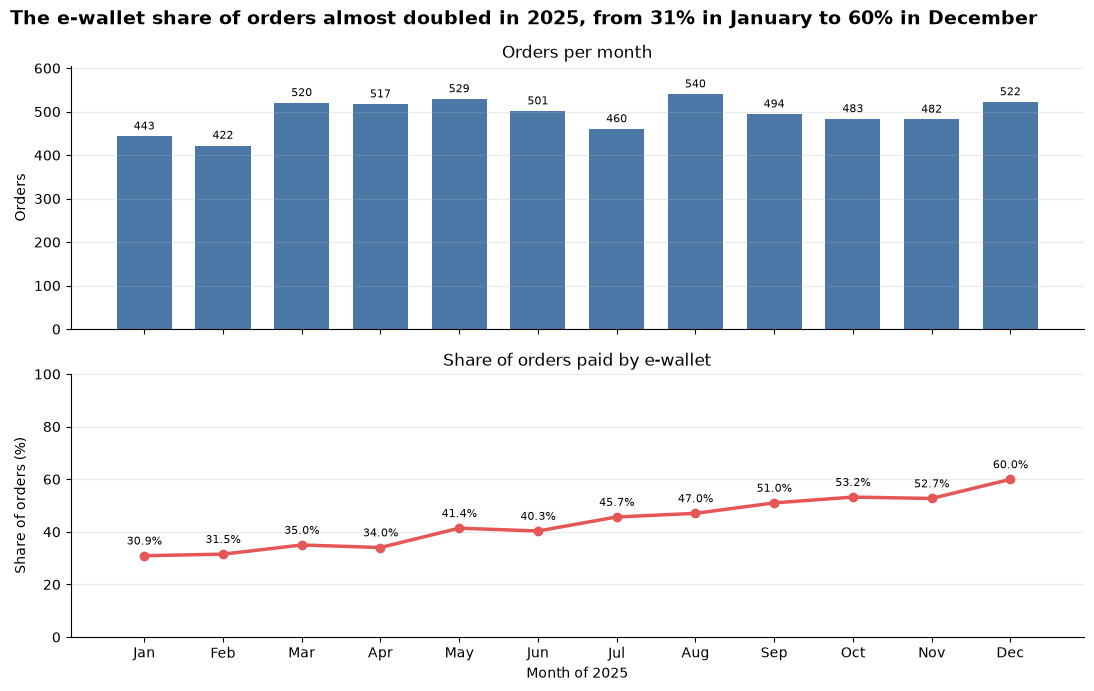

In [9]:
# Chart 2: orders per month (top) and the share of orders paid by e-wallet (bottom), two panels on one month axis.
# My group uses the orders table from Setup, so this cell does not read the CSV file again.
needed = {"order_id", "order_time", "payment"}
missing = needed - set(orders.columns)
if missing:
    raise ValueError(f"The orders table is missing these columns: {sorted(missing)}")

# Number of orders and share of e-wallet payments in each month
monthly = (
    orders.assign(month=orders["order_time"].dt.to_period("M"))
    .groupby("month")
    .agg(
        order_count=("order_id", "size"),
        ewallet_pct=("payment", lambda s: s.eq("E-wallet").mean() * 100),
    )
    .sort_index()
)
months = monthly.index.strftime("%b")          # Jan to Dec, short enough to stay horizontal
first, last = monthly["ewallet_pct"].iloc[0], monthly["ewallet_pct"].iloc[-1]
print(monthly.round(1).to_string())
print(f"E-wallet share: {first:.1f}% in January and {last:.1f}% in December, {last / first:.2f} times as high")

fig2, (ax_orders, ax_wallet) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# Number of orders
bars = ax_orders.bar(months, monthly["order_count"], color="#4C78A8", width=0.7)
ax_orders.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
ax_orders.set_title("Orders per month")
ax_orders.set_ylabel("Orders")
ax_orders.set_ylim(0, monthly["order_count"].max() * 1.12)
ax_orders.grid(axis="y", alpha=0.25)
ax_orders.spines[["top", "right"]].set_visible(False)

# Share of orders paid by e-wallet
ax_wallet.plot(months, monthly["ewallet_pct"], color="#E45756", marker="o", linewidth=2.5)
for month, share_pct in zip(months, monthly["ewallet_pct"]):
    ax_wallet.annotate(
        f"{share_pct:.1f}%",
        (month, share_pct),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8,
    )
ax_wallet.set_title("Share of orders paid by e-wallet")
ax_wallet.set_ylabel("Share of orders (%)")
ax_wallet.set_ylim(0, 100)
ax_wallet.set_xlabel("Month of 2025")
ax_wallet.grid(axis="y", alpha=0.25)
ax_wallet.spines[["top", "right"]].set_visible(False)

fig2.suptitle(f"The e-wallet share of orders almost doubled in 2025, from {first:.0f}% in January to {last:.0f}% in December",
              x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig2.tight_layout()
plt.show()

### Chart 3 · Delivery time
*Task:* find where deliveries are slow, and compare each district's delivery time with its distance to the hub.
*Why this chart:* My group chose horizontal bars sorted by delivery time. The slowest district sits on top, and the bars start at zero, so the length of each bar is honest. The distance in each label answers the second half of the task without a second chart.

*Summary:* My group uses the median of delivered orders, because cancelled orders have no delivery time. The mean gives the same ranking and differs by less than half a minute (see the output below), so the choice does not change the finding. The median describes the typical order.
*Colour:* Every district is grey, and only the districts that are slower than the city median are blue.

In [10]:
# Chart 3: the numbers in the title and the subtitle, checked here
d3 = (delivered.groupby("district")
               .agg(minutes=("delivery_min", "median"), mean=("delivery_min", "mean"),
                    km=("km_to_hub", "first"))
               .sort_values("minutes"))
city = delivered["delivery_min"].median()
slow = d3["minutes"] > city                                   # blue: slower than the city median
per_km = delivered["delivery_min"].cov(delivered["km_to_hub"]) / delivered["km_to_hub"].var()
top, base = d3.index[-1], d3.index[0]

print(d3.round(1).to_string(), "\n")
print("delivered orders without a delivery time:", delivered["delivery_min"].isna().sum())
print(f"largest gap between mean and median: {(d3['mean'] - d3['minutes']).abs().max():.2f} min;",
      "same ranking:", list(d3.sort_values("mean").index) == list(d3.index))
print(f"city median: {city:.1f} min")
print(f"{top} / {base}: {d3.loc[top, 'minutes']:.1f} / {d3.loc[base, 'minutes']:.1f} = "
      f"{d3.loc[top, 'minutes'] / d3.loc[base, 'minutes']:.2f}")
print(f"minutes per extra km: {per_km:.2f}")
print("blue districts = the four farthest from the hub:",
      set(d3.index[slow]) == set(d3["km"].nlargest(4).index))

              minutes  mean    km
district                         
District 1       26.7  26.7   2.1
District 3       29.3  29.1   2.8
District 10      30.7  30.7   3.5
Phu Nhuan        32.2  32.2   4.0
Binh Thanh       33.7  33.6   4.6
Tan Binh         34.9  35.2   5.2
District 7       41.2  41.2   7.5
Go Vap           42.1  41.9   7.9
Binh Tan         49.7  49.6  10.8
Thu Duc City     51.7  51.7  11.5 

delivered orders without a delivery time: 6
largest gap between mean and median: 0.26 min; same ranking: True
city median: 36.3 min
Thu Duc City / District 1: 51.7 / 26.7 = 1.94
minutes per extra km: 2.61
blue districts = the four farthest from the hub: True


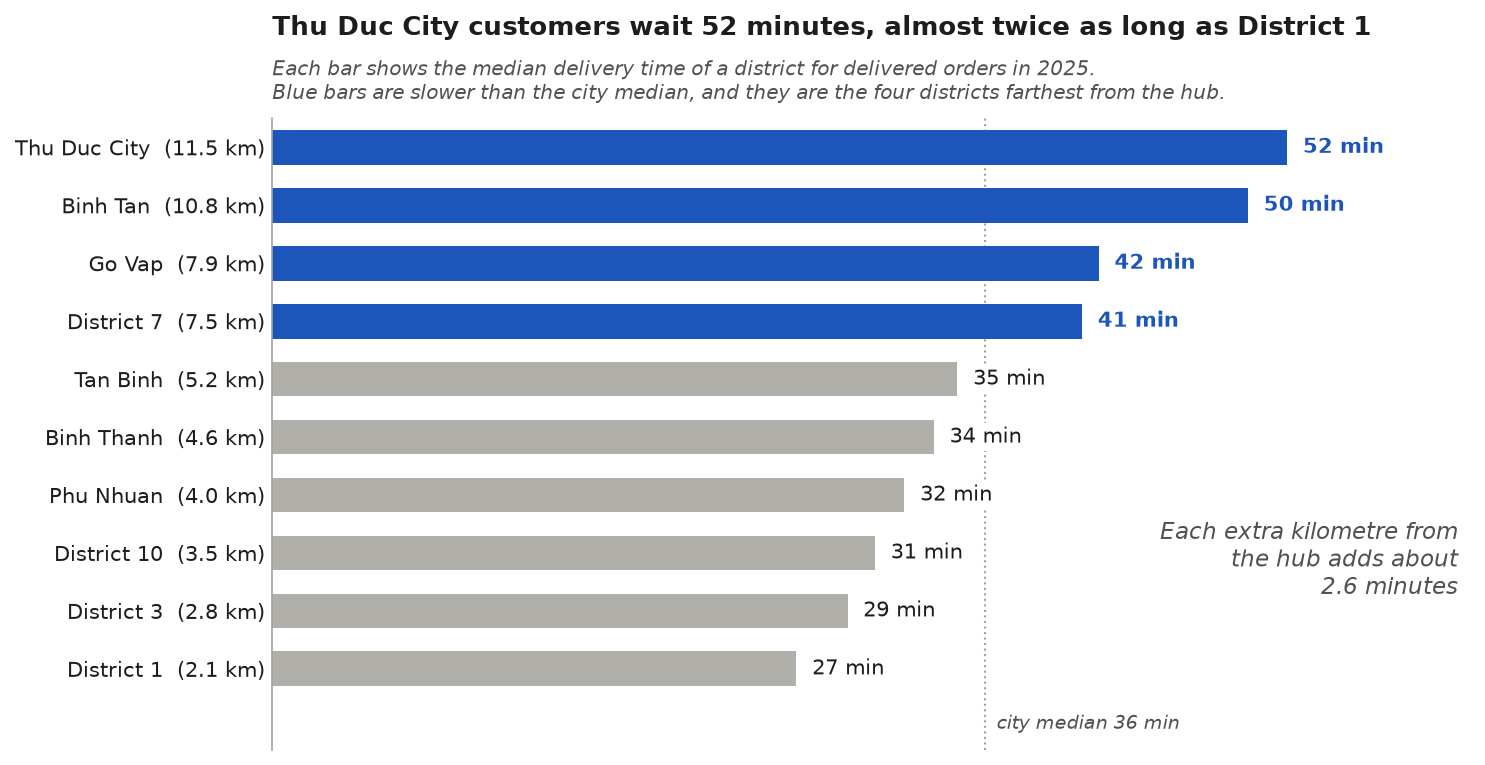

In [11]:
# Chart 3: the slowest district on top, blue only where delivery is slower than the city median
INK, NOTE, AXIS = "#1d1d1b", "#52514e", "#a3a29d"              # same greys as our GH2 charts
BAR, HIGHLIGHT = "#b0afaa", "#1d56ba"

fig3, ax = plt.subplots(figsize=(10, 5.2), dpi=150)
names = [f"{d}  ({km:.1f} km)" for d, km in zip(d3.index, d3["km"])]
bars = ax.barh(names, d3["minutes"], height=0.6, color=np.where(slow, HIGHLIGHT, BAR))
for bar, minutes, is_slow in zip(bars, d3["minutes"], slow):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{minutes:.0f} min", va="center",
            fontsize=10, fontweight="bold" if is_slow else "normal", color=HIGHLIGHT if is_slow else INK,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5))  # readable over the median line
ax.axvline(city, color=AXIS, lw=1, ls=":", zorder=0)
ax.text(city + 0.6, -0.95, f"city median {city:.0f} min", fontsize=9, style="italic", color=NOTE, va="center")
ax.text(0.99, 0.30, f"Each extra kilometre from\nthe hub adds about\n{per_km:.1f} minutes",
        transform=ax.transAxes, ha="right", va="center", fontsize=11, style="italic", color=NOTE)

ax.set_xlim(0, d3["minutes"].max() * 1.18)                     # bars start at zero
ax.set_ylim(-1.4, len(d3) - 0.5)                               # room under the bars for the median label
ax.set_xticks([])                                              # every bar carries its own number
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.spines["left"].set_color(AXIS)
ax.set_title(f"{top} customers wait {d3.loc[top, 'minutes']:.0f} minutes, almost twice as long as {base}",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=40)
ax.text(0, 1.02, "Each bar shows the median delivery time of a district for delivered orders in 2025.\n"
        "Blue bars are slower than the city median, and they are the four districts farthest from the hub.",
        transform=ax.transAxes, fontsize=9.5, style="italic", color=NOTE, va="bottom")
fig3.tight_layout()
plt.show()

### Chart 4 · Peak times
*Task:* find the hours and days with the most orders, so that the operations team can plan staff and riders.
*Why this chart:* My group kept a heatmap because the task needs two dimensions at once, the day and the hour. The days run from Monday to Sunday in calendar order, and a single blue colour map (`Blues`) gets darker as the number of orders grows, so the busiest cells stand out without a rainbow.

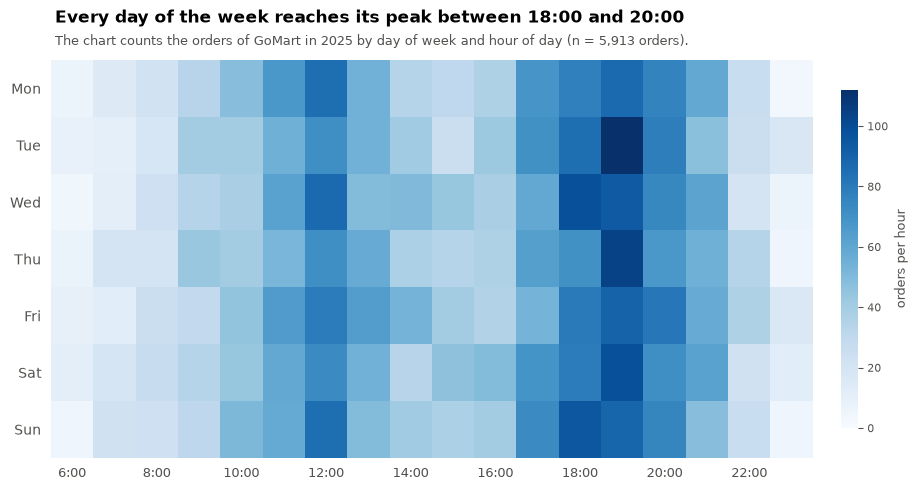

In [12]:
# Chart 4: orders by day and hour, Monday to Sunday in calendar order, one blue colour map
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour

t = orders.pivot_table(index="weekday", columns="hour", values="order_id", aggfunc="count", observed=False).fillna(0)

fig4, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(t.values, cmap="Blues", aspect="auto", vmin=0)

ax.set_yticks(range(len(t.index)))
ax.set_yticklabels(t.index, fontsize=10, color=DARK)

tick_indices = list(range(0, len(t.columns), 2))
ax.set_xticks(tick_indices)
ax.set_xticklabels([f"{t.columns[i]}:00" for i in tick_indices], fontsize=9, color=DARK)

cbar = fig4.colorbar(im, ax=ax, pad=0.03, shrink=0.85)
cbar.set_label("orders per hour", fontsize=9, color=DARK)
cbar.ax.tick_params(labelsize=8, colors=DARK)
cbar.outline.set_visible(False)

for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(left=False, bottom=False)

fig4.text(0.06, 1.05, "Every day of the week reaches its peak between 18:00 and 20:00",
         fontsize=12, weight="bold", color="black", ha="left")
fig4.text(0.06, 1.00, f"The chart counts the orders of GoMart in 2025 by day of week and hour of day (n = {len(orders):,} orders).",
         fontsize=9.5, color=DARK, ha="left")

plt.tight_layout()
plt.show()

In [13]:
# Check the numbers in the Chart 4 title
total_orders = orders.shape[0]
evening_orders = t.loc[:, 18:20].sum().sum()
evening_pct = evening_orders / total_orders * 100
peak_day, peak_h = t.stack().idxmax()
peak_val = t.stack().max()

print(f"Total orders: {total_orders:,}")
print("Busiest hour of each day:", t.idxmax(axis=1).to_dict())
print(f"Orders from 18:00 to 20:59: {evening_orders:,.0f} ({evening_pct:.1f}% of all orders)")
print(f"Single busiest cell: {peak_day} at {peak_h}:00 with {peak_val:.0f} orders")

Total orders: 5,913
Busiest hour of each day: {'Mon': 19, 'Tue': 19, 'Wed': 18, 'Thu': 19, 'Fri': 19, 'Sat': 19, 'Sun': 18}
Orders from 18:00 to 20:59: 1,780 (30.1% of all orders)
Single busiest cell: Tue at 19:00 with 112 orders


### Chart 5 · Targets
*Task:* compare the monthly orders of each zone with its target, and find the zones and months that missed it.
*Why this chart:* My group drew three aligned bar charts, one for each zone, with one shared y axis, so the gaps can be compared across zones. Each bar shows the actual orders minus the target, so the zero line is the target itself, and the signed labels show every surplus and every shortfall.

*Colour:* Blue marks the months above the target, orange marks the months below it, and dark red marks the largest monthly shortfall. My group replaced the red and green of the intern report, because many colour-blind readers cannot separate them.
*Finding:* The Inner zone missed its target by 169 orders over the year, more than Central (113) and Outer (108), and its worst month was November, 61 orders below the target.

In [14]:
# Chart 5: data preparation (the data folder DATA comes from Setup)
data_dir = DATA

orders5 = pd.read_csv(
    data_dir / "gomart_orders_2025_clean.csv",
    parse_dates=["order_time"]
)
districts5 = pd.read_csv(
    data_dir / "gomart_districts.csv"
)
targets5 = pd.read_csv(
    data_dir / "gomart_targets_2025.csv"
)

# Join orders with their zones
orders5 = orders5.merge(
    districts5[["district", "zone"]],
    on="district",
    how="left",
    validate="many_to_one"
)
orders5["month"] = orders5["order_time"].dt.strftime("%Y-%m")

# Count monthly orders by zone
actual5 = (
    orders5.groupby(["zone", "month"])
    .size()
    .reset_index(name="actual_orders")
)

# Compare actual orders with targets
chart5 = targets5.merge(
    actual5,
    on=["zone", "month"],
    how="left",
    validate="one_to_one"
)

chart5["actual_orders"] = (
    chart5["actual_orders"].fillna(0).astype(int)
)
chart5["gap"] = (
    chart5["actual_orders"] - chart5["target_orders"]
)

zone_order5 = ["Central", "Inner", "Outer"]
chart5["zone"] = pd.Categorical(
    chart5["zone"],
    categories=zone_order5,
    ordered=True
)
chart5 = chart5.sort_values(["zone", "month"])

assert len(chart5) == 36
assert chart5["zone"].notna().all()

print(chart5.to_string(index=False))
print("\nTotal gap by zone:")
print(chart5.groupby("zone", observed=True)["gap"].sum())

   zone   month  target_orders  actual_orders  gap
Central 2025-01            116            110   -6
Central 2025-02            117            105  -12
Central 2025-03            123            131    8
Central 2025-04            125            143   18
Central 2025-05            125            137   12
Central 2025-06            136            137    1
Central 2025-07            137            101  -36
Central 2025-08            143            145    2
Central 2025-09            151            122  -29
Central 2025-10            151            123  -28
Central 2025-11            151            133  -18
Central 2025-12            157            132  -25
  Inner 2025-01            196            181  -15
  Inner 2025-02            192            177  -15
  Inner 2025-03            205            240   35
  Inner 2025-04            211            214    3
  Inner 2025-05            211            223   12
  Inner 2025-06            223            220   -3
  Inner 2025-07            232 

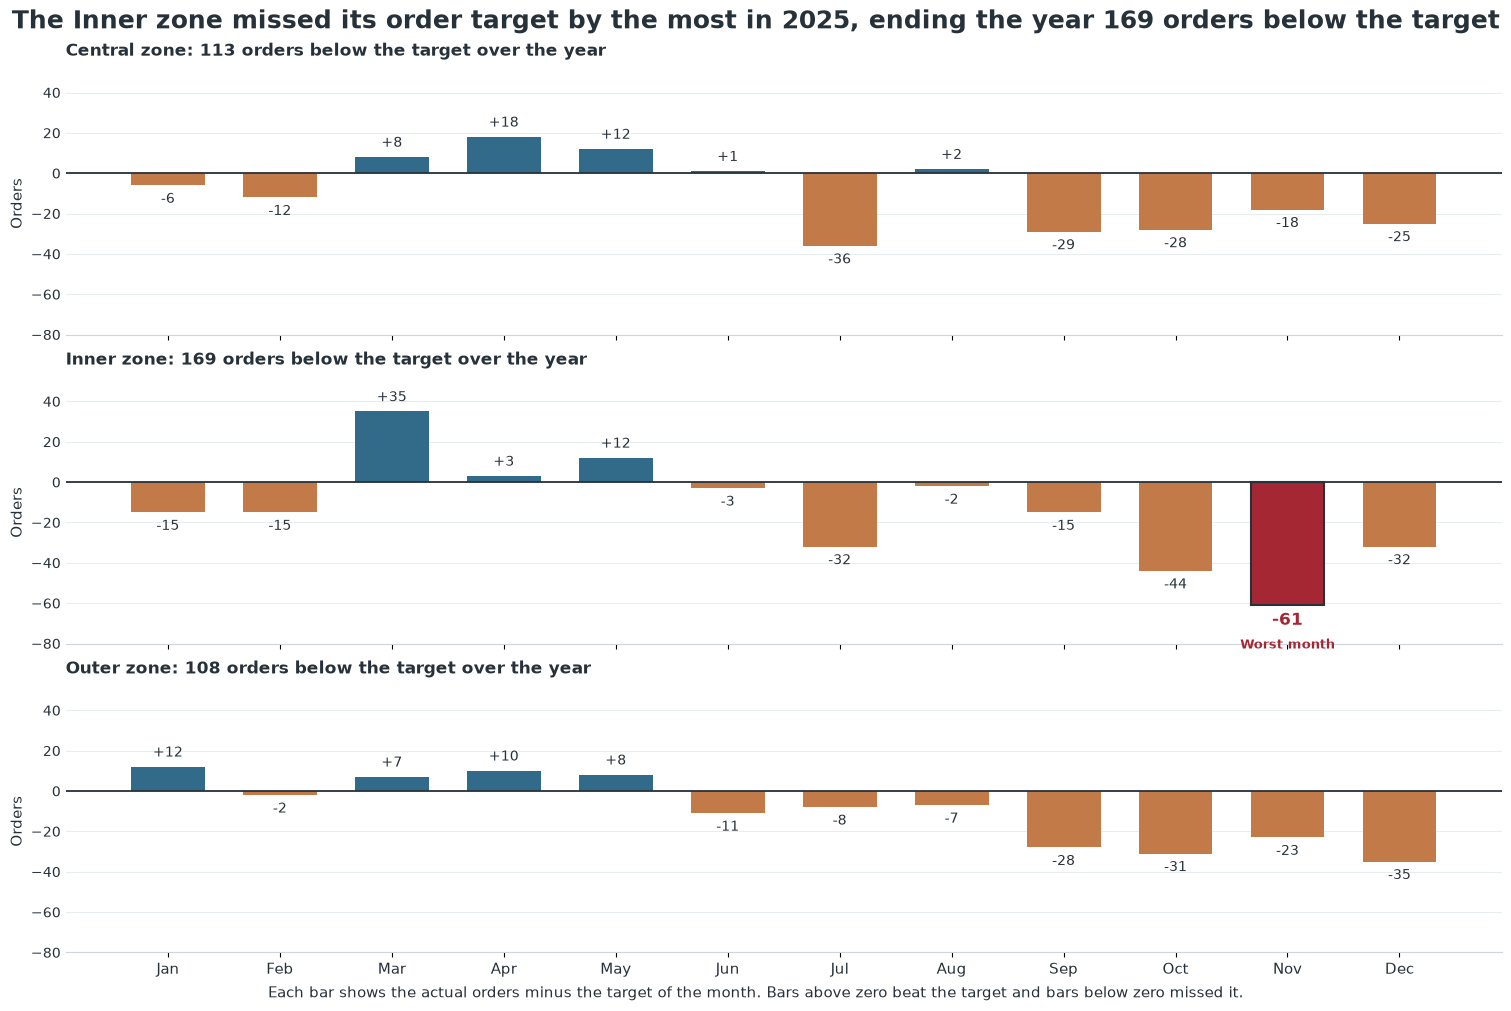

In [15]:
# Chart 5: final redesign, three zones on one shared scale

import numpy as np
import matplotlib.pyplot as plt

# Data from Chart 5 preparation cell
months5 = sorted(chart5["month"].unique())
x5 = np.arange(len(months5))

# Accessible color palette
POS = "#326A8A"       # Above target
NEG = "#C17A48"       # Below target
FOCUS = "#A52734"     # Largest monthly shortfall
TEXT = "#27313A"
GRID = "#E8EDF0"

# Automatically identify the largest monthly shortfall
worst5 = chart5.loc[chart5["gap"].idxmin()]
worst_zone5 = str(worst5["zone"])
worst_month5 = str(worst5["month"])
worst_gap5 = int(worst5["gap"])

# Annual gap by zone
annual5 = (
    chart5.groupby("zone", observed=True)["gap"]
    .sum()
)
annual_worst5 = annual5.idxmin()
annual_gap5 = int(annual5.min())

# Shared Y-axis range for fair comparisons
ymin5 = min(-80, int(chart5["gap"].min()) - 10)
ymax5 = max(50, int(chart5["gap"].max()) + 10)

fig5, axes5 = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, zone in zip(axes5, zone_order5):

    subset = chart5[chart5["zone"] == zone]

    values = (
        subset.set_index("month")
        .reindex(months5)["gap"]
        .to_numpy()
        .astype(int)
    )

    colors = [
        FOCUS if (
            zone == worst_zone5
            and month == worst_month5
        )
        else POS if value >= 0 else NEG
        for month, value in zip(months5, values)
    ]

    bars = ax.bar(
        x5, values,
        width=0.66,
        color=colors,
        zorder=3
    )

    # Zero reference line
    ax.axhline(
        0,
        color=TEXT,
        linewidth=1.3,
        zorder=4
    )

    ax.set_ylim(ymin5, ymax5)

    # Zone heading with annual gap
    ax.set_title(
        f"{zone} zone: {abs(int(annual5[zone]))} orders {'below' if annual5[zone] < 0 else 'above'} the target over the year",
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=TEXT,
        pad=12
    )

    ax.set_ylabel(
        "Orders",
        fontsize=11,
        color=TEXT
    )

    # Subtle grid
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=0.8,
        zorder=0
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CED5DB")
    ax.tick_params(
        axis="y",
        length=0,
        labelsize=10,
        colors=TEXT
    )

    # Signed value labels
    for month, bar, value in zip(months5, bars, values):

        is_focus = (
            zone == worst_zone5
            and month == worst_month5
        )

        ax.annotate(
            f"{value:+d}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(
                0,
                5 if value >= 0 else -5
            ),
            textcoords="offset points",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=12 if is_focus else 10,
            fontweight="bold" if is_focus else "normal",
            color=FOCUS if is_focus else TEXT
        )

        if is_focus:
            bar.set_edgecolor(TEXT)
            bar.set_linewidth(1.5)

    # Highlight the largest shortfall
    if zone == worst_zone5:
        focus_x = months5.index(worst_month5)

        ax.annotate(
            "Worst month",
            xy=(focus_x, worst_gap5),
            xytext=(0, -24),
            textcoords="offset points",
            ha="center",
            va="top",
            fontsize=9,
            fontweight="bold",
            color=FOCUS
        )

# Month labels
axes5[-1].set_xticks(x5)
axes5[-1].set_xticklabels(
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    fontsize=11,
    color=TEXT
)

# Main takeaway
fig5.suptitle(
    f"The {annual_worst5} zone missed its order target by the most in 2025, "
    f"ending the year {abs(annual_gap5)} orders below the target",
    fontsize=18,
    fontweight="bold",
    color=TEXT
)

# Reading guide
fig5.supxlabel(
    "Each bar shows the actual orders minus the target of the month. "
    "Bars above zero beat the target and bars below zero missed it.",
    fontsize=11,
    color=TEXT
)

plt.show()

### Chart 6 · Basket by tier
*Task:* compare the typical basket value across the four member tiers, from non-members to Platinum.
*Why this chart:* My group shows each tier on one row, in the natural order of the tiers, with a dot for the median basket and a bar for the middle half of all orders (25th to 75th percentile). Position on a common scale is easier to compare than the overlapping circles of the intern report, and the bars show how much the baskets of different tiers overlap.

*Summary:* My group uses the median instead of the mean, because basket values are skewed to the right: a few very large baskets pull the mean up. The mean tells the same story (see the output below): Platinum is about a third higher, and the other three tiers lie within about 1% of each other.
*Colour:* Platinum is blue because it is the only tier that differs, and the other three tiers are grey.

In [16]:
# Chart 6: the numbers in the title and the subtitle, checked here
tier_order = ["none", "Silver", "Gold", "Platinum"]
baskets = orders.dropna(subset=["basket_value_vnd"])          # orders without a basket value are left out
d6 = (baskets.groupby("member_tier", observed=True)["basket_value_vnd"]
             .agg(n="count", median="median", mean="mean",
                  q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
             .reindex(tier_order))
above_none = (d6["median"] / d6.loc["none", "median"] - 1) * 100
three = d6.loc[["none", "Silver", "Gold"]]

print(d6.round(0).astype(int).to_string(), "\n")
print("orders without a basket value:", orders["basket_value_vnd"].isna().sum())
print("skewness of the basket value:", round(baskets["basket_value_vnd"].skew(), 2))
print("median above non-members (%):", above_none.round(1).to_dict())
print(f"mean of Platinum above non-members: {(d6.loc['Platinum', 'mean'] / d6.loc['none', 'mean'] - 1) * 100:.1f}%")
print(f"spread of none, Silver and Gold: median {(three['median'].max() / three['median'].min() - 1) * 100:.1f}%, "
      f"mean {(three['mean'].max() / three['mean'].min() - 1) * 100:.1f}%")

                n  median    mean      q1      q3
member_tier                                      
none         4107  237000  252004  169000  315000
Silver       1010  239500  252531  169250  315000
Gold          541  238000  254902  174000  322000
Platinum      230  321500  338657  265000  394000 

orders without a basket value: 25
skewness of the basket value: 0.87
median above non-members (%): {'none': 0.0, 'Silver': 1.1, 'Gold': 0.4, 'Platinum': 35.7}
mean of Platinum above non-members: 34.4%
spread of none, Silver and Gold: median 1.1%, mean 1.2%


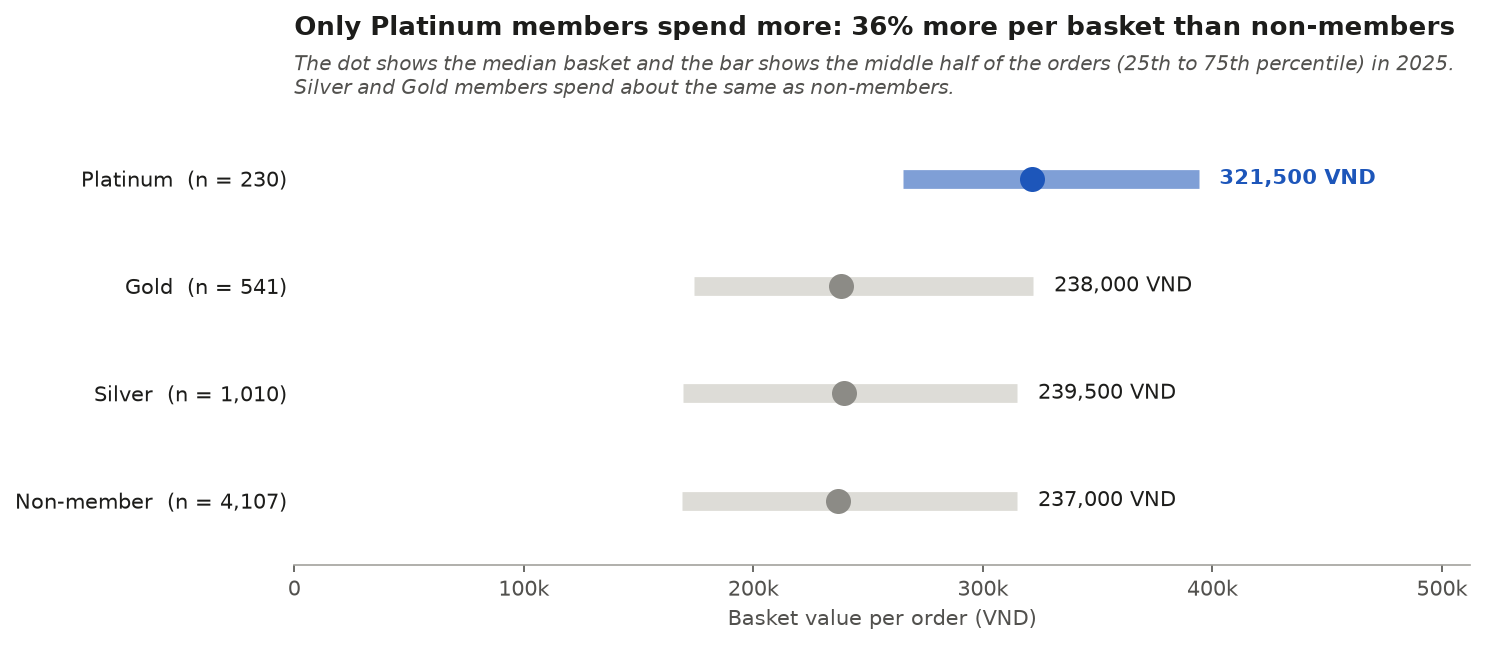

In [17]:
# Chart 6: one row per tier in tier order, a dot for the median and a bar for the middle half of the orders
INK, NOTE, AXIS = "#1d1d1b", "#52514e", "#a3a29d"              # same greys as Chart 3
BAR, HIGHLIGHT = "#8c8b86", "#1d56ba"
BAND_GREY, BAND_BLUE = "#dddcd7", "#7f9fd6"   # solid band colours, chosen after the greyscale test in Task 3
names6 = {"none": "Non-member", "Silver": "Silver", "Gold": "Gold", "Platinum": "Platinum"}

fig6, ax = plt.subplots(figsize=(10, 4.4), dpi=150)
for i, tier in enumerate(d6.index):
    colour = HIGHLIGHT if tier == "Platinum" else BAR
    band = BAND_BLUE if tier == "Platinum" else BAND_GREY
    ax.plot([d6.loc[tier, "q1"], d6.loc[tier, "q3"]], [i, i], color=band, lw=9, solid_capstyle="butt")
    ax.plot(d6.loc[tier, "median"], i, "o", color=colour, ms=11, zorder=3)
    ax.text(d6.loc[tier, "q3"] + 9000, i, f"{d6.loc[tier, 'median']:,.0f} VND", va="center", fontsize=10,
            fontweight="bold" if tier == "Platinum" else "normal", color=HIGHLIGHT if tier == "Platinum" else INK)

ax.set_yticks(range(len(d6)), [f"{names6[t]}  (n = {d6.loc[t, 'n']:,})" for t in d6.index])
ax.set_ylim(-0.6, len(d6) - 0.4)
ax.set_xlim(0, d6["q3"].max() * 1.3)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: "0" if v == 0 else f"{v / 1000:,.0f}k"))
ax.set_xlabel("Basket value per order (VND)", color=NOTE)
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
ax.tick_params(axis="x", colors=NOTE)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.set_title(f"Only Platinum members spend more: {above_none['Platinum']:.0f}% more per basket than non-members",
             loc="left", fontsize=12.5, fontweight="bold", color=INK, pad=38)
ax.text(0, 1.03, "The dot shows the median basket and the bar shows the middle half of the orders (25th to 75th percentile) in 2025.\n"
        "Silver and Gold members spend about the same as non-members.",
        transform=ax.transAxes, fontsize=9.5, style="italic", color=NOTE, va="bottom")
fig6.tight_layout()
plt.show()

**Check.** My group printed the numbers behind every title in a cell next to each chart: the check cell of Chart 1, the cell of Chart 2, the number cells of Chart 3 and Chart 6, the check cell of Chart 4 and the data cell of Chart 5. The cell below saves the six redesigned charts and the Task 0 redesign in the folder `charts/`, so that the lecturer can open them without running the notebook. The folder also holds the original Figure 5 of the NSO report (`task0_nso_figure5_original.png`), the same screenshot that Task 0 shows.

In [18]:
# Save the six redesigned charts and the Task 0 redesign as PNG files in the folder charts/
CHART_FILES = {
    "chart1_orders_by_district.png": fig1,
    "chart2_payments.png": fig2,
    "chart3_delivery_time.png": fig3,
    "chart4_peak_times.png": fig4,
    "chart5_targets.png": fig5,
    "chart6_basket_by_tier.png": fig6,
    "task0_nso_figure5_redesign.png": fig0,
}
Path("charts").mkdir(exist_ok=True)
for name, figure in CHART_FILES.items():
    figure.savefig(Path("charts") / name, dpi=200, bbox_inches="tight", facecolor="white")
print("Files in charts/:", sorted(p.name for p in Path("charts").glob("*.png")))

Files in charts/: ['chart1_orders_by_district.png', 'chart2_payments.png', 'chart3_delivery_time.png', 'chart4_peak_times.png', 'chart5_targets.png', 'chart6_basket_by_tier.png', 'task0_nso_figure5_original.png', 'task0_nso_figure5_redesign.png']


## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

My group ran all six redesigns through both tests and read the outputs below.

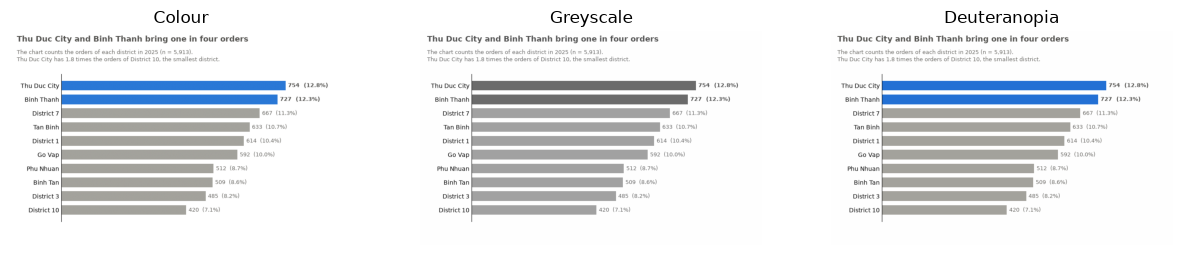

Chart 1 grey values: highlight 0.42, other bars 0.63, gap 0.21
Deuteranopia grey values of highlight / other: [0.4  0.63]


In [19]:
# Task 3: Chart 1 (orders by district) in colour, in greyscale and with simulated deuteranopia
rgb = fig_to_rgb(fig1)
views = {"Colour": rgb, "Greyscale": np.dstack([to_grey(rgb)] * 3), "Deuteranopia": simulate_cvd(rgb)}
fig_t, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (name, img) in zip(axs, views.items()):
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(name); ax.axis("off")
plt.show()
# lightness gap between the highlight and the grey bars (0 = same, 1 = black vs white)
g = lambda c: float(to_grey(np.array(to_rgb(c))))
print(f"Chart 1 grey values: highlight {g(BLUE):.2f}, other bars {g(GREY):.2f}, gap {g(GREY) - g(BLUE):.2f}")
sim = simulate_cvd(np.array([to_rgb(BLUE), to_rgb(GREY)]))
print("Deuteranopia grey values of highlight / other:", np.round(to_grey(sim), 2))

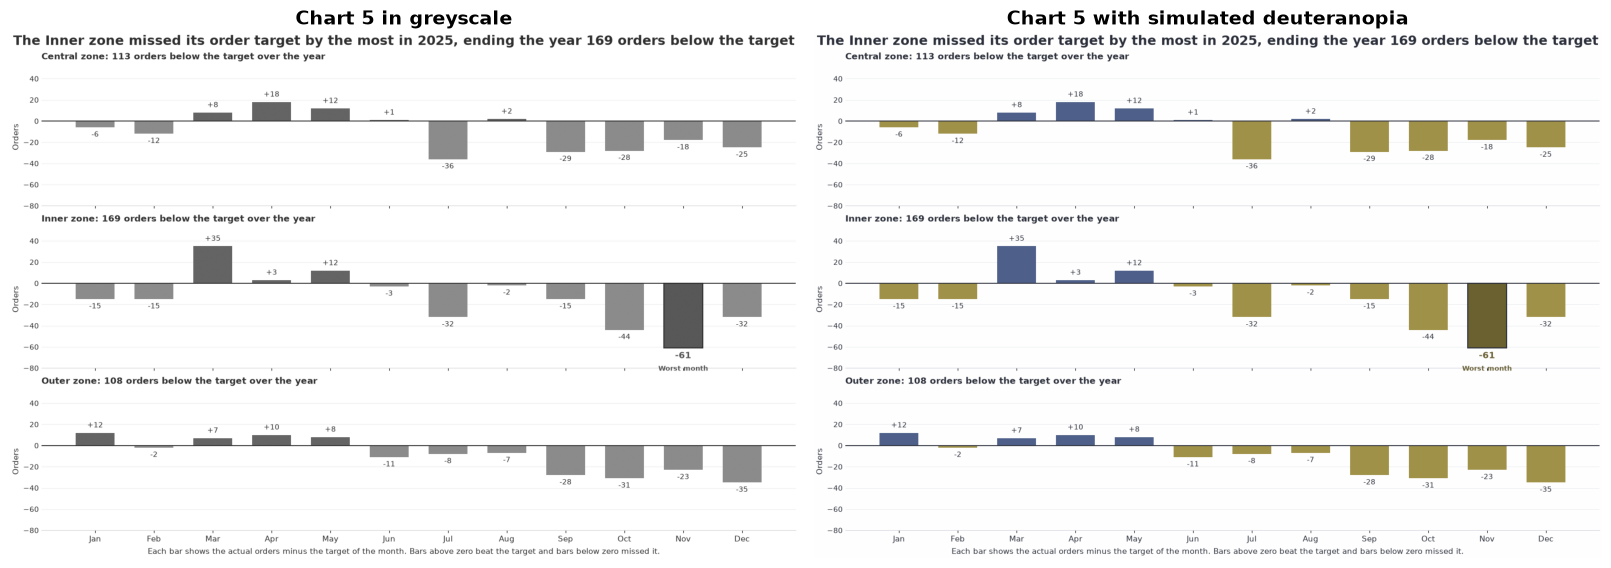

In [20]:
# Task 3: Chart 5 (targets) in greyscale and with simulated deuteranopia

import numpy as np
import matplotlib.pyplot as plt

# Capture the redesigned Chart 5 (fig_to_rgb is defined in Setup)
rgb5 = fig_to_rgb(fig5).astype(float)

# 1. Grayscale simulation (sRGB luminance)
linear5 = np.where(
    rgb5 <= 0.04045,
    rgb5 / 12.92,
    ((rgb5 + 0.055) / 1.055) ** 2.4
)

luminance5 = (
    0.2126 * linear5[..., 0]
    + 0.7152 * linear5[..., 1]
    + 0.0722 * linear5[..., 2]
)

gray5 = np.where(
    luminance5 <= 0.0031308,
    12.92 * luminance5,
    1.055 * luminance5 ** (1 / 2.4) - 0.055
)

# 2. Deuteranopia simulation
matrix5 = np.array([
    [0.367322, 0.860646, -0.227968],
    [0.280085, 0.672501, 0.047413],
    [-0.011820, 0.042940, 0.968881]
])

sim_linear5 = np.clip(
    linear5 @ matrix5.T, 0, 1
)

deuter5 = np.where(
    sim_linear5 <= 0.0031308,
    12.92 * sim_linear5,
    1.055 * sim_linear5 ** (1 / 2.4) - 0.055
)

# Display both tests
fig_test5, ax_test5 = plt.subplots(
    1, 2, figsize=(16, 6),
    constrained_layout=True
)

ax_test5[0].imshow(
    np.clip(gray5, 0, 1),
    cmap="gray",
    vmin=0,
    vmax=1
)
ax_test5[0].set_title(
    "Chart 5 in greyscale",
    fontsize=14, fontweight="bold"
)

ax_test5[1].imshow(
    np.clip(deuter5, 0, 1)
)
ax_test5[1].set_title(
    "Chart 5 with simulated deuteranopia",
    fontsize=14, fontweight="bold"
)

for ax in ax_test5:
    ax.axis("off")

plt.show()

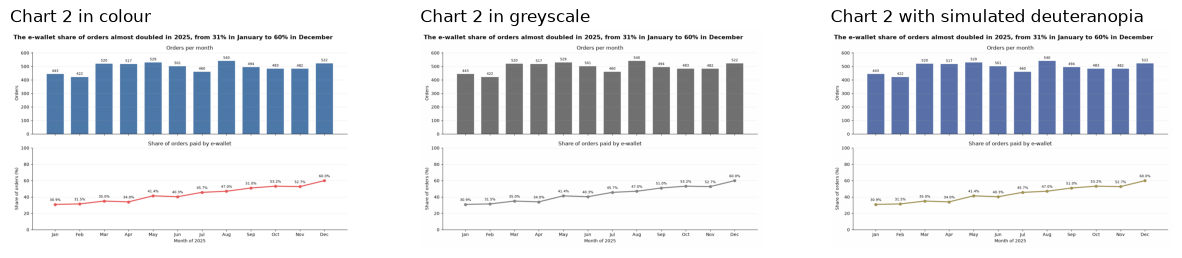

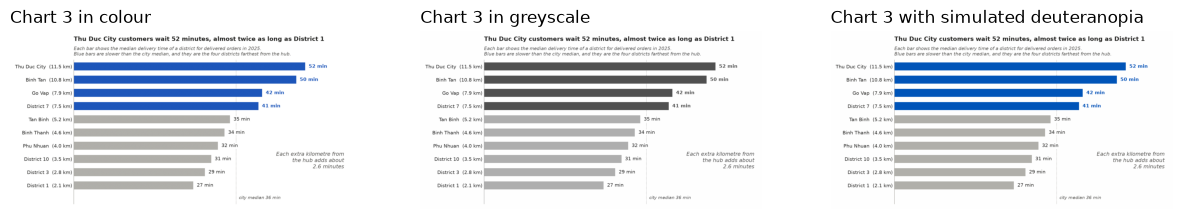

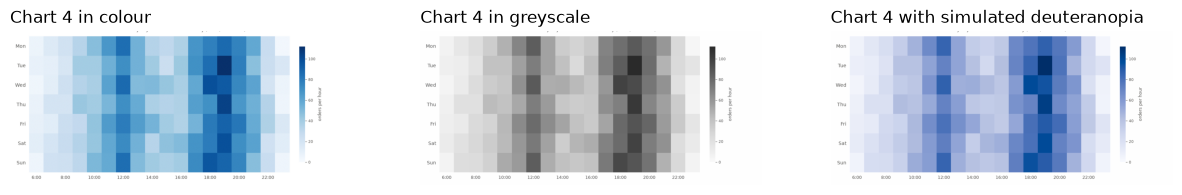

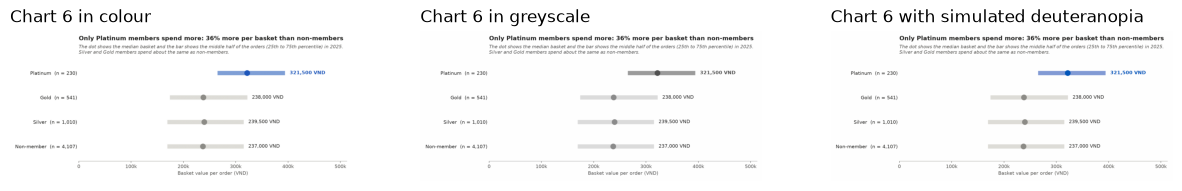

Chart 2, bars and line: lightness gap 0.07 in greyscale and 0.12 with deuteranopia
Chart 3, blue and grey bars: lightness gap 0.37 in greyscale and 0.41 with deuteranopia
Chart 6, blue and grey dots: lightness gap 0.23 in greyscale and 0.27 with deuteranopia
Chart 6, bands in the first version (blue and grey at 35% opacity): lightness gap 0.08 in greyscale and 0.08 with deuteranopia
Chart 6, bands in the final version (solid blue and grey): lightness gap 0.25 in greyscale and 0.26 with deuteranopia


In [21]:
# Task 3: Charts 2, 3, 4 and 6 in colour, in greyscale and with simulated deuteranopia
def show_three_views(figure, name):
    rgb = fig_to_rgb(figure)
    views = {"in colour": rgb, "in greyscale": np.dstack([to_grey(rgb)] * 3),
             "with simulated deuteranopia": simulate_cvd(rgb)}
    test_fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (label, img) in zip(axs, views.items()):
        ax.imshow(np.clip(img, 0, 1)); ax.set_title(f"{name} {label}", loc="left"); ax.axis("off")
    plt.show()


def lightness_gap(colour_a, colour_b, alpha=1.0):
    """Lightness gap between two colours drawn on white (0 = the same grey), in greyscale and with deuteranopia."""
    pair = np.array([to_rgb(colour_a), to_rgb(colour_b)]) * alpha + (1 - alpha)
    return abs(np.diff(to_grey(pair))[0]), abs(np.diff(to_grey(simulate_cvd(pair)))[0])


for figure, name in [(fig2, "Chart 2"), (fig3, "Chart 3"), (fig4, "Chart 4"), (fig6, "Chart 6")]:
    show_three_views(figure, name)

for name, a, b, alpha in [("Chart 2, bars and line", "#4C78A8", "#E45756", 1.0),
                          ("Chart 3, blue and grey bars", "#1d56ba", "#b0afaa", 1.0),
                          ("Chart 6, blue and grey dots", HIGHLIGHT, BAR, 1.0),
                          ("Chart 6, bands in the first version (blue and grey at 35% opacity)", HIGHLIGHT, BAR, 0.35),
                          ("Chart 6, bands in the final version (solid blue and grey)", BAND_BLUE, BAND_GREY, 1.0)]:
    g, d = lightness_gap(a, b, alpha)
    print(f"{name}: lightness gap {g:.2f} in greyscale and {d:.2f} with deuteranopia")

*The change we made because of a test, and why:*

**The test that made us change a chart.** The greyscale test of Chart 6 made my group change the chart. In the first version, the bands for the middle half of the orders were blue and grey at 35% opacity. On white paper both bands became almost the same light grey: the lightness gap was only 0.08 in greyscale and 0.08 with deuteranopia (output above). The Platinum band therefore stopped standing out once the colour was gone. My group replaced the two bands with solid colours that differ in lightness, a mid blue and a light grey, and the gap grew to 0.25 in greyscale and 0.26 with deuteranopia. The change works because the highlight now relies on lightness, which survives a black and white print and colour-vision deficiency, and not only on hue.

**Chart 1** passed both tests without a change. In greyscale the highlighted bars (grey value 0.42) are clearly darker than the other bars (0.63), and with deuteranopia the values stay 0.40 and 0.63, so the highlight does not rely on hue. The design marks the two largest districts with lightness, with their position at the top of the sorted order and with direct labels. The intern pie failed the same test, because `jet` has an uneven lightness and ten hues that merge.

**Chart 2** passed. The bars and the line differ only a little in lightness (a gap of 0.07 in greyscale), but they sit in separate panels and use different marks, so the reader never has to tell them apart by colour.

**Chart 3** passed. The blue bars stay much darker than the grey bars, with a gap of 0.37 in greyscale and 0.41 with deuteranopia.

**Chart 4** passed. The single blue colour map gets darker as the number of orders grows, so the order of the cells survives in greyscale, and deuteranopia barely changes a map with one hue.

**Chart 5** passed. In greyscale the bars above and below the target stay readable through their position against the zero line and their signed labels. With deuteranopia the blue and orange palette stays distinguishable, which is why my group replaced the red and green of the intern report. The worst month, Inner in November with 61 orders below the target, stays easy to find in both views, although the small labels become hard to read when the figure is shrunk.

## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [22]:
def make_stimuli(team_number, path="stimulus_sheet.png"):
    """Perception experiment: one sheet with three panels (bars, pie, bubbles).
    Each panel shows five values A-E; the largest is marked with *. Values differ per panel
    and per team, so every team has its own experiment. Returns the true values (keep them secret)."""
    rng = np.random.default_rng(1000 + team_number)
    truth = {}
    fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))
    for ax, kind in zip(axs, ["bars", "pie", "bubbles"]):
        v = np.round(rng.uniform(10, 90, 5))
        v[rng.integers(5)] = 100                                  # the reference value (only one)
        labels = [L + ("*" if val == 100 else "") for L, val in zip("ABCDE", v)]
        truth[kind] = dict(zip("ABCDE", v.astype(int).tolist()))
        if kind == "bars":
            ax.bar(labels, v, color="white", edgecolor="black")
            ax.set_yticks([]); ax.spines[["top", "right", "left"]].set_visible(False)
        elif kind == "pie":
            ax.pie(v, labels=labels, colors=["white"] * 5, wedgeprops=dict(edgecolor="black"),
                   startangle=90, counterclock=False)
        else:
            ax.scatter(range(5), [0] * 5, s=v / 100 * 2500, color="white", edgecolor="black")
            for i, L in enumerate(labels):
                ax.text(i, -0.55, L, ha="center")
            ax.set_ylim(-0.8, 0.8); ax.set_xlim(-0.7, 4.7); ax.axis("off")
        ax.set_title(f"Panel {['bars', 'pie', 'bubbles'].index(kind) + 1}")
    fig.text(0.5, 0.0, "The value marked * is 100. Estimate the other four values in each panel. "
             "Do not measure; answer within 30 seconds per panel.", ha="center", fontsize=10)
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return truth

In [23]:
# Make the stimulus sheet for team 10. The true values stay in `truth`; they are not printed.
truth = make_stimuli(team_number=10)
print("Sheet saved as stimulus_sheet.png;", {k: len(v) for k, v in truth.items()}, "values per panel")

Sheet saved as stimulus_sheet.png; {'bars': 5, 'pie': 5, 'bubbles': 5} values per panel


### 4.2 Protocol (fill in before you collect)

**Who:** people who do not take this course. Each member collects at least 3 respondents and is recorded as `collector`. Each collector codes respondents R01, R02 and so on, and no names are recorded. In `experiment_answers.csv` the code also carries the collector's name (for example `tuan-anh-R01`), because every collector starts at R01. Four members collected answers, and my group collected 15 respondents in total, which meets the minimum of 15 in the brief. To reach the 19 respondents that my group planned, my group added four simulated respondents (see *Placeholder respondents* below).

**How:** each respondent receives the same file `stimulus_sheet.png` privately (not in a group chat), so no one sees another person's answers.

**Task:** estimate by eye the four unmarked values in each panel, taking the value marked \* as 100. In the pie panel the question is "how large is this slice compared with the slice marked \*", not a percentage of the whole pie. About 30 seconds per panel; no ruler.

**No help:** the same wording for everyone; no hints, no true values, no comments on the answers.

**Recording:** one answer per item, typed in the format `Panel 1: A=__ B=__ D=__ E=__`; a screenshot of each reply (name hidden, time visible) goes to `evidence/`. An answer given as a range is recorded as its middle; "about half" is recorded as 50. Some respondents answered with fractions of the marked value (for example "3/4 of C\*"), and my group multiplied the fraction by 100 (3/4 becomes 75).

**Cleaning:** my group made three decisions about odd answers before the analysis. First, one respondent wrote "8" for a bubble in a sheet of fractions, and my group read it as 8 out of 100. Second, one respondent wrote "C = 7/8" in the bar panel, where C is the marked bar, and my group read it as D. Third, respondents 4 to 6 of one collector repeat the answers of respondent 3 to the last digit. My group kept all six respondents of that collector, because the collector surveyed six people, and cell 4.3 also shows the results without the repeats.

**Placeholder respondents:** the simulated respondents `sim-R01` to `sim-R04` are made by `scripts/build_experiment_answers.py`. For every item the script takes the answer of a randomly chosen collected respondent, changes it by about 5% and rounds it. They carry the collector `simulated`, they have no sheet in `evidence/`, and they add no new information. They only fill the table to 19 respondents, and every result below is shown with and without them.

**Consent:** the purpose and the "no name" rule were stated before the respondent answered.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

My group's table has 19 respondents and 228 estimates. It holds 15 collected respondents and 4 simulated ones (`collector = simulated`). The cell below checks the table, computes the log error and shows every result twice, for all 19 respondents and for the 15 collected ones, so that the reader can see how much the placeholders change.

In [24]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [25]:
# Task 4.3: log_error for all 19 respondents, summarised by encoding
answers = pd.read_csv("experiment_answers.csv")
answers["source"] = np.where(answers["collector"] == "simulated", "simulated", "collected")

# Two checks before we use the table: every `true` is the value printed on stimulus_sheet.png, and every respondent has 12 estimates
assert (answers["true"] == [truth[e][i] for e, i in zip(answers["encoding"], answers["item"])]).all()
assert (answers.groupby("respondent").size() == 12).all()

answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
answers["abs_error"] = (answers["judged"] - answers["true"]).abs()
answers["signed_error"] = answers["judged"] - answers["true"]
collected = answers[answers["source"] == "collected"]
print("Respondents:", answers.groupby("source")["respondent"].nunique().to_dict(), "| estimates:", len(answers),
      "| collectors:", answers["collector"].unique().tolist())


def summarise(df, seed=0):
    """Mean errors by encoding and a 95% bootstrap interval over respondents (resample respondents, then average their errors)."""
    rng = np.random.default_rng(seed)
    summ = df.groupby("encoding").agg(mean_log_error=("log_error", "mean"), mean_abs_error=("abs_error", "mean"),
                                      n=("log_error", "count")).round(2)
    per = df.groupby(["encoding", "respondent"])["log_error"].mean().unstack()        # encoding x respondent
    intervals = {}
    for enc in per.index:
        vals = per.loc[enc].dropna().to_numpy()
        boots = [rng.choice(vals, size=len(vals), replace=True).mean() for _ in range(5000)]
        intervals[enc] = np.percentile(boots, [2.5, 97.5])
    return summ, per, intervals


n_all, n_col = answers["respondent"].nunique(), collected["respondent"].nunique()
summary, per_resp, ci = summarise(answers)            # all respondents
summary_c, per_resp_c, ci_c = summarise(collected)    # only the collected respondents
print(pd.concat({f"all {n_all}": summary, f"collected {n_col}": summary_c}, axis=1))
print(f"95% intervals, all {n_all}:", {k: np.round(v, 2).tolist() for k, v in ci.items()})
print(f"95% intervals, collected {n_col}:", {k: np.round(v, 2).tolist() for k, v in ci_c.items()})

# Do the simulated rows behave like the collected ones? (mean log error of each group)
print(answers.groupby(["source", "encoding"])["log_error"].mean().unstack().round(2))


# Every respondent judged all three panels, so we can also compare the encodings inside each respondent (paired difference)
def paired_gap(per, worse, better="bars", seed=0):
    diff = (per.loc[worse] - per.loc[better]).dropna().to_numpy()
    rng = np.random.default_rng(seed)
    boots = [rng.choice(diff, size=len(diff), replace=True).mean() for _ in range(5000)]
    return diff.mean(), np.percentile(boots, [2.5, 97.5])


for name, per in {f"all {n_all}": per_resp, f"collected {n_col}": per_resp_c}.items():
    for worse, better in [("pie", "bars"), ("bubbles", "bars"), ("bubbles", "pie")]:
        m, (lo, hi) = paired_gap(per, worse, better)
        print(f"{name}: {worse} minus {better} = {m:+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}]")


# Some collected respondents may repeat an earlier respondent to the last digit. As a check, here are the results without the repeats.
wide = collected.pivot_table(index="respondent", columns=["encoding", "item"], values="judged")
repeats = wide.index[wide.duplicated(keep="first")].tolist()
summary_u, per_resp_u, ci_u = summarise(collected[~collected["respondent"].isin(repeats)])
print("Respondents that repeat an earlier respondent:", repeats)
print("Mean log error without them:", summary_u["mean_log_error"].to_dict(), "| respondents left:", per_resp_u.shape[1])

Respondents: {'collected': 15, 'simulated': 4} | estimates: 228 | collectors: ['tuan-anh', 'minh-nguyet', 'quang-minh', 'thao', 'simulated']


                 all 19                      collected 15                   
         mean_log_error mean_abs_error   n mean_log_error mean_abs_error   n
encoding                                                                    
bars               1.75           4.71  76           1.65           4.39  60
bubbles            2.60           9.82  76           2.66          10.34  60
pie                2.41           7.10  76           2.59           7.66  60
95% intervals, all 19: {'bars': [1.49, 2.03], 'bubbles': [2.12, 3.06], 'pie': [2.03, 2.75]}
95% intervals, collected 15: {'bars': [1.38, 1.96], 'bubbles': [2.08, 3.19], 'pie': [2.21, 2.93]}
encoding   bars  bubbles   pie
source                        
collected  1.65     2.66  2.59
simulated  2.09     2.39  1.73
all 19: pie minus bars = +0.66, 95% interval [+0.26, +1.02]
all 19: bubbles minus bars = +0.86, 95% interval [+0.34, +1.45]
all 19: bubbles minus pie = +0.19, 95% interval [-0.31, +0.76]
collected 15: pie minus bars = +0.93,

collected 15: bubbles minus pie = +0.07, 95% interval [-0.41, +0.60]
Respondents that repeat an earlier respondent: ['thao-R04', 'thao-R05', 'thao-R06']
Mean log error without them: {'bars': 1.67, 'bubbles': 2.78, 'pie': 2.58} | respondents left: 12


### 4.4 Result chart

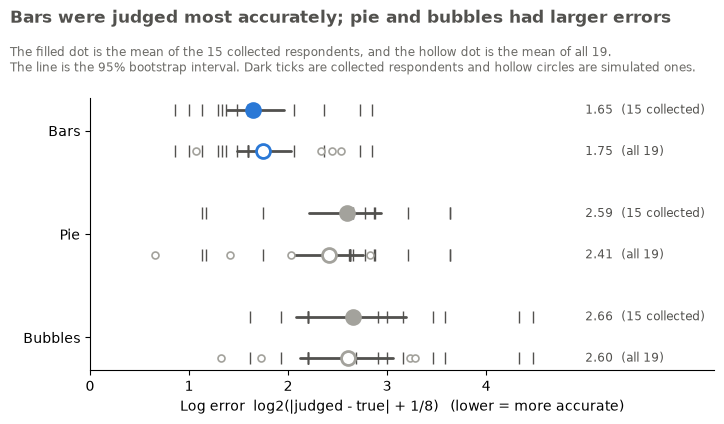

In [26]:
# 4.4 Result chart: mean log error by encoding, 95% bootstrap interval over respondents.
# For each encoding, the upper line uses the collected respondents and the lower line uses all respondents.
order = summary_c["mean_log_error"].sort_values().index.tolist()          # best (lowest error) first
sim_ids = answers.loc[answers["source"] == "simulated", "respondent"].unique()
lines = [(f"{n_col} collected", per_resp_c, ci_c, summary_c, -0.2, True), (f"all {n_all}", per_resp, ci, summary, 0.2, False)]
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, enc in enumerate(order):
    for label, per, intervals, summ, dy, filled in lines:
        y, m = i + dy, summ.loc[enc, "mean_log_error"]
        colour = BLUE if enc == order[0] else GREY
        ax.plot(intervals[enc], [y, y], color=DARK, lw=2, solid_capstyle="round")
        ax.plot(m, y, "o", color=colour if filled else "white", markeredgecolor=colour,
                markeredgewidth=2, ms=10, zorder=3)
        shown = per.loc[enc].dropna()
        is_sim = shown.index.isin(sim_ids)
        ax.plot(shown[~is_sim], [y] * (~is_sim).sum(), "|", color=DARK, ms=9)                       # collected respondents
        ax.plot(shown[is_sim], [y] * is_sim.sum(), "o", mfc="white", mec=GREY, ms=5, mew=1.2)       # simulated respondents
        ax.text(5.0, y, f"{m:.2f}  ({label})", va="center", fontsize=8.5, color=DARK)
ax.set_yticks(range(len(order)), [e.capitalize() for e in order]); ax.invert_yaxis()
ax.set_xlim(0, 6.3)
ax.set_xticks(range(5))
ax.set_xlabel("Log error  log2(|judged - true| + 1/8)   (lower = more accurate)")
ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Bars were judged most accurately; pie and bubbles had larger errors", x=0.02, ha="left", fontweight="bold", color=DARK)
n_sim = len(sim_ids)
sub = f"The filled dot is the mean of the {n_col} collected respondents, and the hollow dot is the mean of all {n_all}.\n"
sub += "The line is the 95% bootstrap interval. Dark ticks are collected respondents" + (" and hollow circles are simulated ones." if n_sim else ".")
fig.text(0.02, 0.9, sub, fontsize=8.5, color="#6b6a66", va="top")
fig.subplots_adjust(top=0.78, left=0.12, bottom=0.16)
plt.show()

**Which items were hardest.** The chart shows the mean absolute error of each of the 12 items, in points, for the 15 collected respondents.

encoding item  true  mean_abs_error  bias
 bubbles    C    89            15.2  -0.2
     pie    B    55            10.5   1.5
 bubbles    D    65            10.1   4.8
 bubbles    E    78             9.3   2.2
     pie    A    43             8.8  -2.0
Easiest: [['bars', 'E', 4.6], ['bars', 'B', 4.3], ['bars', 'A', 2.6]]


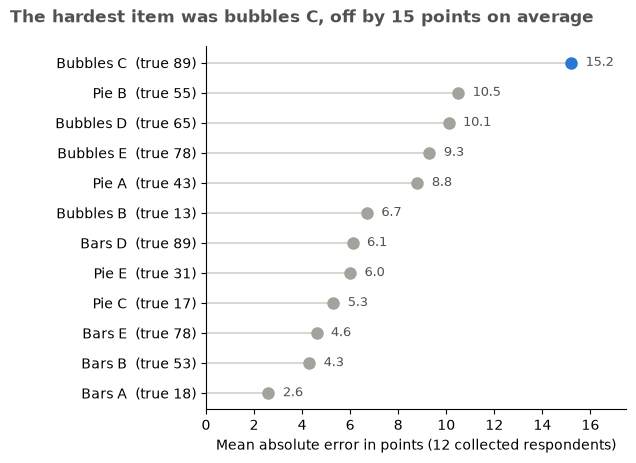

In [27]:
# Which items were hardest? Mean absolute error in points for each of the 12 items, collected respondents only
items = (collected.groupby(["encoding", "item"])
         .agg(true=("true", "first"), mean_abs_error=("abs_error", "mean"), bias=("signed_error", "mean"))
         .round(1).reset_index().sort_values("mean_abs_error", ascending=False))
print(items.head(5).to_string(index=False))
print("Easiest:", items.tail(3)[["encoding", "item", "mean_abs_error"]].values.tolist())
by_item = items.sort_values("mean_abs_error")
fig_items, ax = plt.subplots(figsize=(7, 4.6))
for i, r in enumerate(by_item.itertuples()):
    hard = r.Index == items.index[0]
    ax.plot([0, r.mean_abs_error], [i, i], color=LIGHT, lw=1.5, zorder=1)
    ax.plot(r.mean_abs_error, i, "o", color=BLUE if hard else GREY, ms=8, zorder=3)
    ax.text(r.mean_abs_error + 0.6, i, f"{r.mean_abs_error:.1f}", va="center", fontsize=9, color=DARK)
ax.set_yticks(range(len(by_item)), [f"{r.encoding.capitalize()} {r.item}  (true {r.true})" for r in by_item.itertuples()])
ax.set_xlim(0, by_item["mean_abs_error"].max() * 1.15)
ax.set_xlabel("Mean absolute error in points (12 collected respondents)")
ax.spines[["top", "right"]].set_visible(False)
top = items.iloc[0]
fig_items.suptitle(f"The hardest item was {top['encoding']} {top['item']}, off by {top['mean_abs_error']:.0f} points on average",
                   x=0.02, ha="left", fontweight="bold", color=DARK)
fig_items.subplots_adjust(top=0.9, left=0.3)
plt.show()

### 4.5 Interpretation (at most 150 words)
My group's result agrees with Cleveland and McGill (1984) in direction. Bars had the lowest mean log error (1.65 for the 15 collected respondents and 1.75 with all 19), then pie (2.59) and bubbles (2.66). Within respondents, pie was 0.93 worse than bars and bubbles 1.01 worse, and both 95% intervals stay above zero, while pie and bubbles do not differ clearly. The order holds without the repeated respondents. The hardest item was bubbles C (true 89), with a mean error of 15 points, because area is hard to compare and two respondents answered 12.5 and 50.

**Limitations.** First, my group collected 15 respondents, which meets the minimum of 15, and the simulated rows only fill the table, so my group trusts the collected respondents. Second, the sample is not random, answers came as numbers or fractions, and every respondent saw the panels in the same order.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2 and 3.

Rush hours: [11, 12, 18, 19, 20] | share of all orders: 46.49%
Median delivery minutes by zone:
 hour    other  rush
zone               
Central  24.1  32.4
Inner    31.5  39.1
Outer    44.2  52.5
Extra minutes in rush hours: {'Central': 8.2, 'Inner': 7.6, 'Outer': 8.3} | all deliveries: 8.1
Rating by delivery time:
               mean  count
delivery_min             
up to 25      4.62    365
25 to 35      4.26   1264
35 to 45      3.29   1168
45 to 55      2.42    680
over 55       2.21    192
Rated orders: 3,669 of 5,607 delivered | correlation of rating and delivery time: -0.74
Average rating in rush hours / other hours: {False: 3.82, True: 3.22} | city median delivery time: 36.3


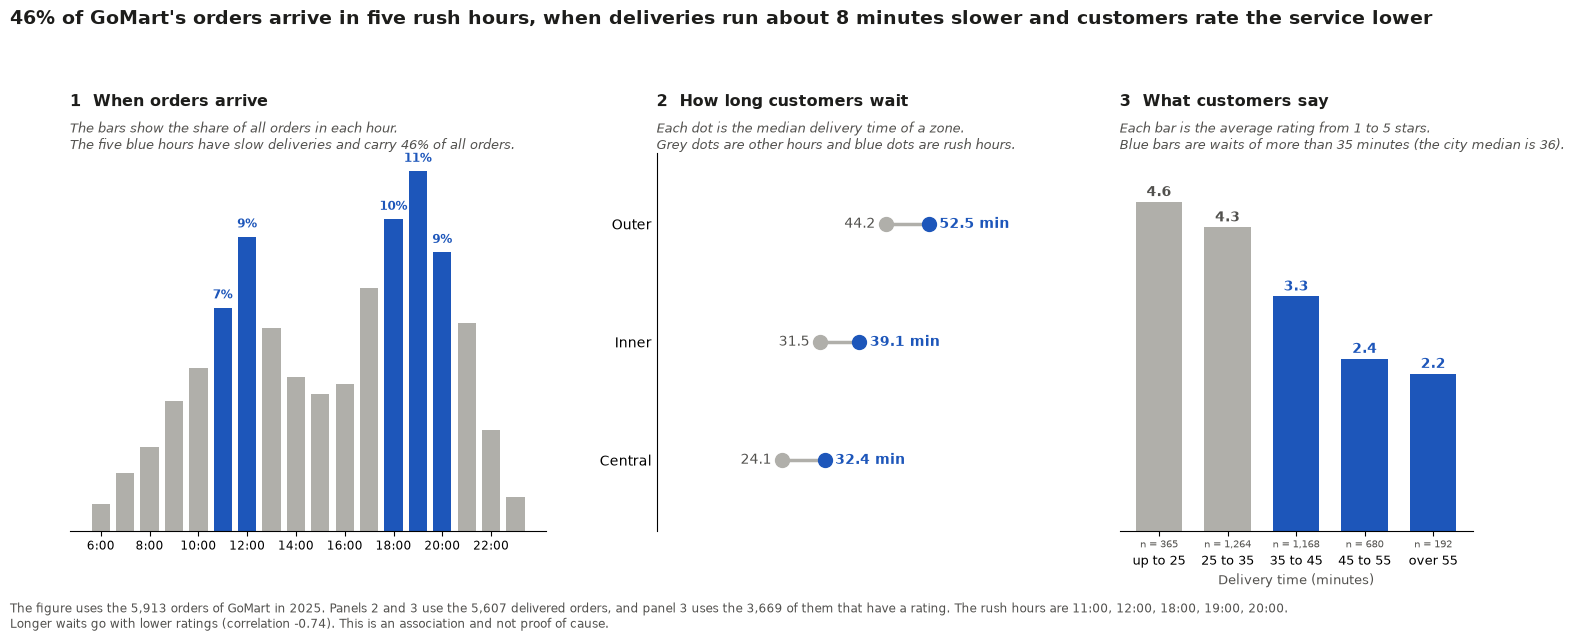

In [28]:
# Task 5: one figure, three panels, one action title.
# Colours as in Tasks 2 and 3: the blue of Chart 3 marks what the reader should look at, grey is everything else.
BLUE5, GREY5, INK5, NOTE5 = "#1d56ba", "#b0afaa", "#1d1d1b", "#52514e"

# The rush hours come from the data: the hours whose median delivery time is more than 5 minutes above the typical hour
hour_median = delivered.groupby("hour")["delivery_min"].median()
rush_hours = hour_median.index[hour_median > hour_median.median() + 5].tolist()
is_rush = delivered["hour"].isin(rush_hours)

orders_by_hour = orders["hour"].value_counts().sort_index()
rush_share = orders["hour"].isin(rush_hours).mean() * 100
zone_minutes = delivered.groupby(["zone", is_rush])["delivery_min"].median().unstack()          # columns: False, True
zone_minutes = zone_minutes.rename(columns={False: "other", True: "rush"}).sort_values("rush")
extra = zone_minutes["rush"] - zone_minutes["other"]

rated = delivered.dropna(subset=["rating", "delivery_min"])
band_edges, band_names = [0, 25, 35, 45, 55, np.inf], ["up to 25", "25 to 35", "35 to 45", "45 to 55", "over 55"]
bands = pd.cut(rated["delivery_min"], band_edges, labels=band_names)
rating_by_band = rated.groupby(bands, observed=True)["rating"].agg(["mean", "count"])
city_median = delivered["delivery_min"].median()
corr = rated["rating"].corr(rated["delivery_min"])
rating_rush = rated.groupby(rated["hour"].isin(rush_hours))["rating"].mean()

print("Rush hours:", rush_hours, "| share of all orders:", f"{rush_share:.2f}%")
print("Median delivery minutes by zone:\n", zone_minutes.map(lambda v: f"{v:.1f}").to_string())
print("Extra minutes in rush hours:", extra.round(1).to_dict(), "| all deliveries:",
      round(delivered.loc[is_rush, "delivery_min"].median() - delivered.loc[~is_rush, "delivery_min"].median(), 1))
print("Rating by delivery time:\n", rating_by_band.round(2).to_string())
print(f"Rated orders: {len(rated):,} of {len(delivered):,} delivered | correlation of rating and delivery time: {corr:.2f}")
print("Average rating in rush hours / other hours:", rating_rush.round(2).to_dict(), "| city median delivery time:", round(city_median, 1))

fig5p = plt.figure(figsize=(15, 6.4))
gs5 = fig5p.add_gridspec(1, 3, width_ratios=[1.35, 1, 1], wspace=0.28)
ax_h, ax_z, ax_r = (fig5p.add_subplot(gs5[0, i]) for i in range(3))

# Panel 1: orders by hour, blue where deliveries are slow
colors = [BLUE5 if h in rush_hours else GREY5 for h in orders_by_hour.index]
ax_h.bar(orders_by_hour.index, orders_by_hour.values / len(orders) * 100, color=colors, width=0.75)
for h in rush_hours:
    ax_h.text(h, orders_by_hour[h] / len(orders) * 100 + 0.3, f"{orders_by_hour[h] / len(orders) * 100:.0f}%", ha="center",
              fontsize=8.5, color=BLUE5, fontweight="bold")
ax_h.set_xticks(range(6, 24, 2), [f"{h}:00" for h in range(6, 24, 2)], fontsize=8.5)
ax_h.set_yticks([])
ax_h.spines[["top", "right", "left"]].set_visible(False)
ax_h.set_title("1  When orders arrive", loc="left", fontsize=11.5, fontweight="bold", color=INK5, pad=34)
ax_h.text(0, 1.0, f"The bars show the share of all orders in each hour.\nThe five blue hours have slow deliveries and carry {rush_share:.0f}% of all orders.",
          transform=ax_h.transAxes, fontsize=9, color=NOTE5, style="italic", va="bottom")

# Panel 2: median delivery time by zone, rush hours against the other hours
for y, (zone, row) in enumerate(zone_minutes.iterrows()):
    ax_z.plot([row["other"], row["rush"]], [y, y], color=GREY5, lw=2.5, zorder=1)
    ax_z.plot(row["other"], y, "o", color=GREY5, ms=10, zorder=3)
    ax_z.plot(row["rush"], y, "o", color=BLUE5, ms=10, zorder=3)
    ax_z.text(row["other"] - 2.0, y, f"{row['other']:.1f}", ha="right", va="center", fontsize=10, color=NOTE5)
    ax_z.text(row["rush"] + 2.0, y, f"{row['rush']:.1f} min", ha="left", va="center", fontsize=10, color=BLUE5, fontweight="bold")
ax_z.set_yticks(range(len(zone_minutes)), [f"{z}" for z in zone_minutes.index], fontsize=10)
ax_z.set_ylim(-0.6, len(zone_minutes) - 0.4)
ax_z.set_xlim(0, 68)
ax_z.set_xticks([])
ax_z.tick_params(axis="y", length=0)
ax_z.spines[["top", "right", "bottom"]].set_visible(False)
ax_z.set_title("2  How long customers wait", loc="left", fontsize=11.5, fontweight="bold", color=INK5, pad=34)
ax_z.text(0, 1.0, "Each dot is the median delivery time of a zone.\nGrey dots are other hours and blue dots are rush hours.", transform=ax_z.transAxes,
          fontsize=9, color=NOTE5, style="italic", va="bottom")

# Panel 3: average rating by delivery time. Blue: slower than the city median (as in Chart 3)
slow_band = [i for i, lo in enumerate(band_edges[:-1]) if lo >= 35]                 # waits of more than 35 minutes
x = np.arange(len(rating_by_band))
ax_r.bar(x, rating_by_band["mean"], color=[BLUE5 if i in slow_band else GREY5 for i in x], width=0.68)
for i, (m, n) in enumerate(zip(rating_by_band["mean"], rating_by_band["count"])):
    ax_r.text(i, m + 0.08, f"{m:.1f}", ha="center", fontsize=10, color=BLUE5 if i in slow_band else NOTE5, fontweight="bold")
    ax_r.text(i, -0.12, f"n = {n:,}", ha="center", va="top", fontsize=7.5, color=NOTE5)
ax_r.set_xticks(x, rating_by_band.index, fontsize=9)
ax_r.tick_params(axis="x", pad=14)
ax_r.set_ylim(0, 5.3)
ax_r.set_yticks([])
ax_r.spines[["top", "right", "left"]].set_visible(False)
ax_r.set_xlabel("Delivery time (minutes)", color=NOTE5, fontsize=9, labelpad=4)
ax_r.set_title("3  What customers say", loc="left", fontsize=11.5, fontweight="bold", color=INK5, pad=34)
ax_r.text(0, 1.0, f"Each bar is the average rating from 1 to 5 stars.\nBlue bars are waits of more than 35 minutes (the city median is {city_median:.0f}).", transform=ax_r.transAxes,
          fontsize=9, color=NOTE5, style="italic", va="bottom")

fig5p.suptitle(f"{rush_share:.0f}% of GoMart's orders arrive in five rush hours, when deliveries run about "
               f"{extra.mean():.0f} minutes slower and customers rate the service lower",
               x=0.01, ha="left", fontsize=14, fontweight="bold", color=INK5, y=0.985)
fig5p.text(0.01, 0.012, f"The figure uses the {len(orders):,} orders of GoMart in 2025. Panels 2 and 3 use the {len(delivered):,} delivered orders, "
           f"and panel 3 uses the {len(rated):,} of them that have a rating. The rush hours are {', '.join(f'{h}:00' for h in rush_hours)}.\n"
           f"Longer waits go with lower ratings (correlation {corr:.2f}). This is an association and not proof of cause.",
           fontsize=8.5, color=NOTE5, va="bottom")
fig5p.subplots_adjust(top=0.76, bottom=0.17, left=0.05, right=0.985)
plt.show()

Path("charts").mkdir(exist_ok=True)
fig5p.savefig(Path("charts") / "task5_one_page.png", dpi=200, bbox_inches="tight", facecolor="white")

**Why these three panels.** In my group's opinion, the operations director has to decide when and where to put riders, so the figure answers three questions in a row. The first panel shows when orders arrive, with bars by hour. The second panel shows how long customers wait, with the median delivery time of each zone in rush hours and in the other hours as two dots on one scale. The third panel shows what that wait does to the ratings, with one bar from zero for each delivery-time band. Blue means the same in all three panels, the slow side, as in Chart 3. Grey is everything else, and every value is labelled, so the figure needs no legend and no gridlines. My group did not pick the rush hours by hand. The cell takes the hours whose median delivery time is more than 5 minutes above the typical hour. The note under the figure says that the link between rating and delivery time is an association.

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| Nguyễn Hoàng Minh (leader) | Repository, Setup, Task 0, Chart 3, Chart 6, Task 3, merging, Task 4 table and analysis, Task 5, Task 6 | 3 respondents | 100% |
| Phạm Quang Minh | Task 0, Chart 2 | 3 respondents | 100% |
| Phạm Tuấn Anh | Task 0, Chart 1, Task 4 first version | 3 respondents | 100% |
| Nguyễn Minh Nguyệt | Task 0, Chart 5 | 3 respondents | 100% |
| Trần Nguyễn Thanh Thảo | Task 0, Chart 4 | 6 respondents | 100% |
| Trần Nhã Đoan | Task 0, Chart 6 | 7 respondents | 100% |

All six members worked on Task 0 together. My group split the shares by the work listed above. The simulated respondents of Task 4 are not credited to any member.

In [29]:
AI_USE = """
Tool(s) used:
Claude Code (model Claude Sonnet 5.5), run by the team leader in the editor on the leader's branch hwinh. My group used it as an assistant for
orientation and helper code, and my group made the decisions.

What we asked:
1. Orientation: to read the brief and the notebook and list what was still missing before the hand-in.
2. Helper code: a script that turns the typed survey answers into experiment_answers.csv, the code for the log error, the bootstrap intervals and
   the two result charts of Task 4, and the layout code of the one-page figure of Task 5.
3. Placeholder rows: four simulated respondents, built from the collected ones, so that the table reaches the 19 respondents that my group planned.
4. First drafts of the wording of Tasks 4.2 to 6 and a check of the wording of the other tasks, in the style of the rest of the notebook.

What we checked or changed ourselves:
1. The ideas and the decisions are ours. My group designed the experiment (stimulus sheet and protocol), collected the 15 respondents, decided how
   each odd answer is read (listed in 4.2), and made the audit, the redesigns, the colours and the tests of Tasks 0 to 3 and the Big Idea of Task 5.
2. Every finding in a title or in the text comes from an output that a member read next to it, and a check cell prints the numbers. The table of
   Task 4 also passes two checks in code: every `true` value matches the stimulus sheet and every respondent has 12 estimates.
3. The simulated respondents are labelled everywhere (sim-R01 to sim-R04, collector simulated). Task 4 shows each result with and
   without them, and the interpretation relies on the collected respondents.
4. My group keeps AI-written wording and code only after a member has run the notebook from top to bottom (Restart and run all), read the
   outputs next to the text and edited the text where it did not match what my group did.
"""
print(AI_USE)


Tool(s) used:
Claude Code (model Claude Sonnet 5.5), run by the team leader in the editor on the leader's branch hwinh. My group used it as an assistant for
orientation and helper code, and my group made the decisions.

What we asked:
1. Orientation: to read the brief and the notebook and list what was still missing before the hand-in.
2. Helper code: a script that turns the typed survey answers into experiment_answers.csv, the code for the log error, the bootstrap intervals and
   the two result charts of Task 4, and the layout code of the one-page figure of Task 5.
3. Placeholder rows: four simulated respondents, built from the collected ones, so that the table reaches the 19 respondents that my group planned.
4. First drafts of the wording of Tasks 4.2 to 6 and a check of the wording of the other tasks, in the style of the rest of the notebook.

What we checked or changed ourselves:
1. The ideas and the decisions are ours. My group designed the experiment (stimulus sheet and protoc